# TP2 - Etapa 2: entrenamiento, evaluación y comparación de modelos

Notebook de entrenamiento y estudio de resultados: evaluación de la búsqueda por similitud
(Etapa 1, NDCG@10), fine-tuning de ResNet (Modelo A), CNN propia (Modelo B) y comparación entre
modelos (ver `ENUNCIADO.md`, secciones 4.3 y 5). **Ambos modelos son obligatorios.**

El entrenamiento se realiza en Colab para aprovechar la GPU:
**Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)**.

Requisitos previos (en tu fork):
- Funciones de la Etapa 1 implementadas en `src/lib/services/similarity_service.py`.
- `train_classifier`, `evaluate_classifier` y `extract_custom_embedding` implementadas en
  `src/lib/services/classifier_service.py` (esta notebook solo las orquesta).
- Splits y conjunto independiente generados en `1-pre-processing.ipynb`.

Al finalizar:
- Descargar los checkpoints generados y colocarlos en `models/` del entorno local
  (la aplicación los usa en las pestañas de las Etapas 1, 2 y 3).
- Publicarlos en un link público de solo lectura para los docentes.
- Entregar esta notebook ejecutada, con sus salidas.

**Notebook en Google Colab:** no corresponde. Esta notebook se entrega ejecutada en el repositorio, con sus salidas (ver `ENUNCIADO.md`, sección 8.2).

## Equipo
- Lucas Ramirez — R-4727/9 — @lucasramire
- Valentín Lujambio — L-3417/7 — @valentinlujambio

## 1. Entorno

La notebook corre en Colab (GPU T4) o localmente desde la raíz del repositorio. En Colab:

- Se monta Google Drive y ahí se guardan **checkpoints, historiales y resultados de experimentos**
  (`MyDrive/tp2-perros/`): si Colab se desconecta no se pierde nada, y al volver a ejecutar las celdas
  los experimentos ya terminados no se repiten.
- El dataset se copia al disco local de la máquina (`/content`), no se lee desde Drive: leer miles de
  JPG chicos desde Drive hace que la GPU espere al disco.

Si el fork es privado, usar un token de acceso en `REPO_URL` (no dejarlo escrito en la notebook entregada).

In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/lucasramire/tuia-dog-recognition-app.git"
BRANCH = "feature/valentin-lujambio"  # pasar a main cuando este integrado

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    if not Path("/content/proyecto").exists():
        !git clone --branch $BRANCH $REPO_URL /content/proyecto
    %cd /content/proyecto
    !git log --oneline -1
    !pip install -q pydantic-settings python-dotenv kagglehub albumentations onnx onnxruntime ultralytics imagehash
print("Colab:", IN_COLAB)

Mounted at /content/drive
Cloning into '/content/proyecto'...
remote: Enumerating objects: 530, done.
remote: Counting objects: 100% (134/134), done.
remote: Compressing objects: 100% (45/45), done.
remote: Total 530 (delta 115), reused 92 (delta 89), pack-reused 396 (from 3)
Receiving objects: 100% (530/530), 12.69 MiB | 19.52 MiB/s, done.
Resolving deltas: 100% (296/296), done.
/content/proyecto
5115891 (HEAD -> feature/valentin-lujambio, origin/feature/valentin-lujambio) docs: README con modelos, resultados y problemas de las etapas 2 y 3
Colab: True


## 2. Configuración

Las rutas se fijan como variables de entorno **antes** de importar `lib` (igual que en
`1-pre-processing.ipynb`). Sin pgvector: la evaluación usa matrices de numpy.

In [2]:
import json
import logging
import os
import shutil
import time
from dataclasses import asdict

ROOT = Path.cwd()
assert (ROOT / "src" / "lib").is_dir(), "Ejecutar la notebook desde la raiz del repositorio"
PERSIST = Path("/content/drive/MyDrive/tp2-perros") if IN_COLAB else ROOT
os.environ.update(
    {
        "USE_PGVECTOR": "false",
        "DATA_PATH": str(ROOT / "data"),
        "DATASET_PATH": str(ROOT / "data" / "dataset"),
        "EMBEDDINGS_PATH": str(ROOT / "data" / "embeddings.json"),
        "OUTPUT_PATH": str(PERSIST / "output"),
        "MODEL_PATH": str(PERSIST / "models"),
        "TORCH_HOME": str(ROOT / "models" / "torch"),
        "YOLO_MODEL": str(ROOT / "models" / "yolov8n.pt"),
    }
)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from lib.config import settings

logging.getLogger().setLevel(logging.WARNING)
logging.getLogger("lib.training").setLevel(logging.INFO)  # una linea por epoca
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 140)

DATASET = settings.dataset_path
EXP_DIR = settings.output_path / "experiments"
for d in (settings.model_path, EXP_DIR):
    d.mkdir(parents=True, exist_ok=True)
SEED = 42
NUM_WORKERS = min(4, os.cpu_count() or 1)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("dataset:", DATASET)
print("checkpoints:", settings.model_path, "| experimentos:", EXP_DIR)
print("GPU:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "no", "| workers:", NUM_WORKERS)

dataset: /content/proyecto/data/dataset
checkpoints: /content/drive/MyDrive/tp2-perros/models | experimentos: /content/drive/MyDrive/tp2-perros/output/experiments
GPU: Tesla T4 | workers: 2


## 3. Dataset y splits

El dataset se descarga con `scripts/download_dataset.py` (kagglehub; si pide credenciales, cargar
`KAGGLE_USERNAME` y `KAGGLE_KEY` en los *secrets* de Colab). En Colab se guarda además un zip en Drive
para no volver a descargarlo.

Los splits son los de `1-pre-processing.ipynb`: `data/splits/splits_v1.csv` (sin fugas entre splits ni
duplicados; `valid` y `test` con 10 imágenes por raza). Todo lo que sigue usa **solo `train` y `valid`
para elegir**; `test` se mira una vez por modelo final.

In [3]:
ZIP = PERSIST / "dataset.zip"
if not (DATASET / "dogs.csv").exists():
    if IN_COLAB and ZIP.exists():
        shutil.unpack_archive(str(ZIP), str(DATASET))
    else:
        !python scripts/download_dataset.py
        if IN_COLAB:
            shutil.make_archive(str(ZIP.with_suffix("")), "zip", str(DATASET))
# Conjunto independiente (imagenes fuera de git, D-29): en Colab, desde un zip en Drive.
INDEPENDENT_ZIP = PERSIST / "independent_v1.zip"
if IN_COLAB and INDEPENDENT_ZIP.exists() and not (DATASET / "independent").exists():
    shutil.unpack_archive(str(INDEPENDENT_ZIP), str(DATASET))
print(sorted(p.name for p in DATASET.iterdir() if not p.name.startswith(".")))

['dogs.csv', 'independent', 'test', 'train', 'valid']


In [4]:
from lib.dataset.manifest import class_names, load_manifest

MANIFEST = settings.data_path / "splits" / "splits_v1.csv"
manifest = load_manifest(MANIFEST, dataset_path=DATASET, check_files=True)
CLASSES = class_names(manifest)
counts = manifest.groupby(["breed", "split"]).size().unstack(fill_value=0)[["train", "valid", "test"]]
display(counts.agg(["sum", "min", "median", "max"]).T)
print(f"{len(CLASSES)} razas | train por raza: {counts['train'].min()} a {counts['train'].max()} "
      f"({counts['train'].max() / counts['train'].min():.1f} veces)")

,sum,min,median,max
split,,,,
train,7198.0,56.0,101.5,185.0
valid,700.0,10.0,10.0,10.0
test,700.0,10.0,10.0,10.0


70 razas | train por raza: 56 a 185 (3.3 veces)


## 5. Etapa 1 — Evaluación de la búsqueda por similitud (baseline)

**Protocolo** (enunciado 4.3). Galería: las 7.198 imágenes de `train`. Consultas: las 700 de `test` y las imágenes
de raza del conjunto independiente (`1-pre-processing.ipynb`, sección 7). Ninguna consulta está en la galería
(verificado en la sección 10 de la notebook 1). Embeddings: el baseline de `extract_embedding`, ResNet50
`IMAGENET1K_V1` sin `fc` (2048 dimensiones), con el mismo preprocesamiento de la app.

- **NDCG@10**: `ndcg_at_k` provista, con relevancia binaria (misma raza) y `n_relevant` = imágenes de la raza en la
  galería, así un único acierto en el primer lugar no da 1.
- **precision@10**: fracción de los 10 vecinos que son de la raza de la consulta.
- **accuracy**: la raza predicha es la de la consulta. Se predice con la misma función que usa la app
  (`predict_breed_from_neighbors`, voto ponderado por similitud entre los `TOP_K` vecinos).

Sin base de datos: los embeddings se guardan en matrices de NumPy y la búsqueda es un producto matricial
(`lib/evaluation/retrieval.py`, que calcula los scores con la misma fórmula que `SimilarityService.similarity`).
Se calculan una vez y quedan en cache.

In [5]:
import shutil

# Conjunto independiente: en Colab se descomprime desde Drive (independent_v1.zip en MyDrive/tp2-perros/).
INDEPENDENT_ZIP = PERSIST / "independent_v1.zip"
if not (DATASET / "independent").exists() and IN_COLAB and INDEPENDENT_ZIP.exists():
    shutil.unpack_archive(str(INDEPENDENT_ZIP), str(DATASET))
assert (DATASET / "independent").exists(), "Falta data/dataset/independent/ (descomprimir independent_v1.zip dentro de data/dataset/)"

from lib.dataset.independent import load_registry

registry = load_registry(settings.data_path / "splits" / "independent_v1.csv")
independent = registry[registry["scene"] == "single"].reset_index(drop=True)
print(f"Consultas del conjunto independiente: {len(independent)} imagenes de {independent['breed'].nunique()} razas")

Consultas del conjunto independiente: 118 imagenes de 20 razas


In [6]:
from lib.evaluation import retrieval as R
from lib.models.baseline import BaselineEmbedder

STAGE1_DIR = settings.output_path / "stage1"
embedder = BaselineEmbedder(settings.image_size)
embed_raw = lambda images: embedder.embed_batch(images, normalize=False)  # crudos: para comparar con l2 (D-11)

raw = R.load_or_compute_embeddings(
    STAGE1_DIR / "baseline_raw_splits.npz", manifest["path"].tolist(),
    [DATASET / p for p in manifest["path"]], embed_raw,
)
raw_ind = R.load_or_compute_embeddings(
    STAGE1_DIR / "baseline_raw_independent.npz", independent["path"].tolist(),
    [DATASET / p for p in independent["path"]], embed_raw,
)
emb, emb_ind = R.l2_normalize(raw), R.l2_normalize(raw_ind)  # lo que guarda la app
split = manifest["split"].to_numpy()
breeds = manifest["breed"].to_numpy()
gallery, test_q = split == "train", split == "test"
print("galeria:", gallery.sum(), "| consultas test:", test_q.sum(), "| consultas independiente:", len(independent))

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /content/proyecto/models/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 192MB/s]


galeria: 7198 | consultas test: 700 | consultas independiente: 118


### 5.1 Resultados con la configuración de la app

`cosine` sobre embeddings normalizados, `TOP_K` de la configuración y sin umbral (cada consulta recibe una raza).
Intervalos bootstrap del 95 % (2.000 remuestreos de las consultas).

In [7]:
TOP_K = settings.top_k
sim_test = R.similarity_matrix(emb[test_q], emb[gallery], "cosine")
sim_ind = R.similarity_matrix(emb_ind, emb[gallery], "cosine")
ev_test = R.evaluate_queries(sim_test, breeds[test_q], breeds[gallery], ndcg_k=10, vote_k=TOP_K)
ev_ind = R.evaluate_queries(sim_ind, independent["breed"].to_numpy(), breeds[gallery], ndcg_k=10, vote_k=TOP_K)

stage1 = pd.DataFrame({"test": ev_test.summary(seed=SEED), "independiente": ev_ind.summary(seed=SEED)}).T
for m in ("ndcg@10", "precision@10", "accuracy"):
    stage1[m] = [f"{r[m]:.3f} [{r[m + '_low']:.3f}; {r[m + '_high']:.3f}]" for _, r in stage1.iterrows()]
display(stage1[["n", "ndcg@10", "precision@10", "accuracy"]])

print("Razas con peor NDCG@10 en test (10 consultas por raza: valores ruidosos):")
display(R.per_breed_table(ev_test.per_query).head(8).round(3))
print("Razas del conjunto independiente con peor NDCG@10 (5 a 8 consultas por raza):")
display(R.per_breed_table(ev_ind.per_query).head(6).round(3))

,n,ndcg@10,precision@10,accuracy
test,700.0,0.902 [0.887; 0.917],0.896 [0.881; 0.912],0.943 [0.924; 0.960]
independiente,118.0,0.716 [0.662; 0.772],0.707 [0.653; 0.762],0.797 [0.720; 0.864]


Razas con peor NDCG@10 en test (10 consultas por raza: valores ruidosos):


,n,ndcg,precision,accuracy
raza,,,,
Bulldog,10,0.417,0.40,0.5
Cockapoo,10,0.571,0.57,0.7
American Hairless,10,0.600,0.59,0.6
Lhasa,10,0.605,0.58,0.7
Boston Terrier,10,0.621,0.62,0.9
Shih-Tzu,10,0.664,0.69,0.8
Japanese Spaniel,10,0.704,0.71,0.7
Labradoodle,10,0.718,0.69,1.0


Razas del conjunto independiente con peor NDCG@10 (5 a 8 consultas por raza):


,n,ndcg,precision,accuracy
raza,,,,
Labradoodle,5,0.373,0.320,0.400
Cockapoo,5,0.387,0.380,0.400
Boston Terrier,6,0.408,0.433,0.333
Poodle,5,0.534,0.500,0.800
Shih-Tzu,6,0.556,0.583,0.667
Bulldog,6,0.570,0.567,0.667


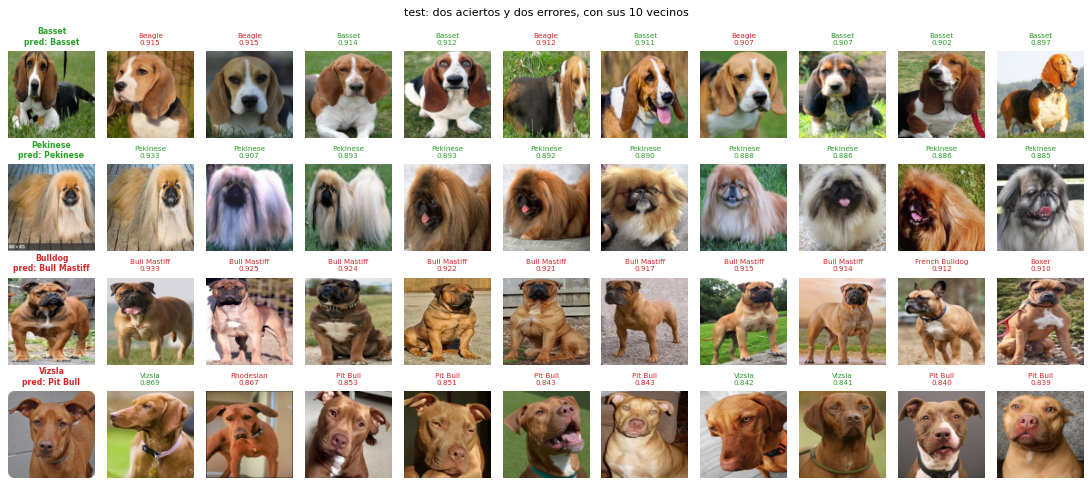

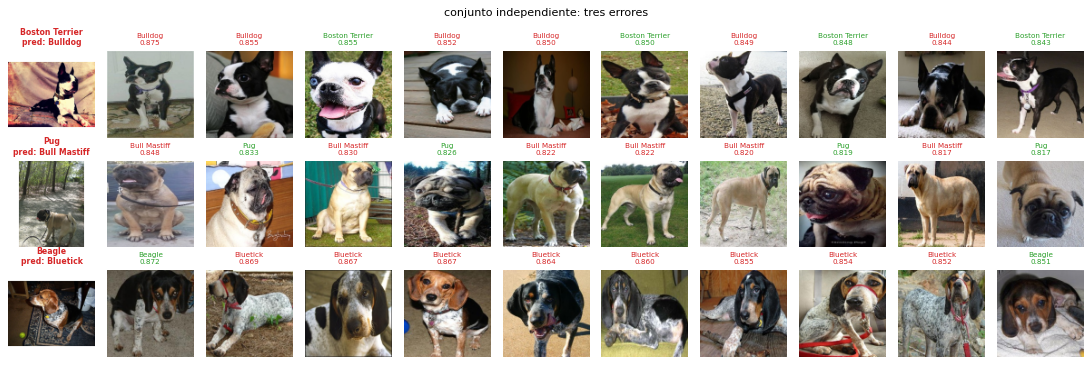

In [8]:
from lib.visualization.retrieval import show_query_results

gallery_paths = (DATASET / manifest.loc[gallery, "path"]).to_numpy()
gallery_breeds = breeds[gallery]


def query_rows(ev, query_paths, idx):
    pq = ev.per_query
    return [
        {"query_path": query_paths[i], "query_breed": pq.loc[i, "query_breed"], "predicted_breed": pq.loc[i, "predicted_breed"],
         "neighbor_paths": gallery_paths[ev.neighbors[i, :10]], "neighbor_breeds": gallery_breeds[ev.neighbors[i, :10]],
         "neighbor_scores": ev.neighbor_scores[i, :10]}
        for i in idx
    ]


test_paths = (DATASET / manifest.loc[test_q, "path"]).to_numpy()
ind_paths = (DATASET / independent["path"]).to_numpy()
rng = np.random.default_rng(SEED)
pq = ev_test.per_query
hits = rng.choice(pq.index[pq["correct"]], 2, replace=False)
misses = rng.choice(pq.index[~pq["correct"]], 2, replace=False)
show_query_results(query_rows(ev_test, test_paths, list(hits) + list(misses)), size=96,
                   suptitle="test: dos aciertos y dos errores, con sus 10 vecinos")
plt.show()
pqi = ev_ind.per_query
show_query_results(query_rows(ev_ind, ind_paths, rng.choice(pqi.index[~pqi["correct"]], 3, replace=False)), size=96,
                   suptitle="conjunto independiente: tres errores")
plt.show()

**Lectura.**

- **En `test` la búsqueda funciona muy bien**: NDCG@10 0,902 [0,887; 0,917], precision@10 0,896 y accuracy 0,943 [0,924; 0,960]. El baseline sin entrenar ya separa las razas, porque ImageNet incluye unas 118 razas de perro entre sus clases.
- **En el conjunto independiente cae bastante**: NDCG@10 0,716 [0,662; 0,772] y accuracy 0,797 [0,720; 0,864]. Los intervalos no se superponen con los de `test`: es el cambio de dominio (otras fuentes, encuadres y relaciones de aspecto; `1-pre-processing.ipynb`, sección 7), no ruido.
- **Las peores razas son los pares que se confunden**, en los dos conjuntos: Bulldog, Cockapoo, Lhasa y Shih-Tzu, Boston Terrier en `test`; Labradoodle, Cockapoo y Boston Terrier en el independiente. Con 5 a 10 consultas por raza los valores por raza son descriptivos: un error mueve 10 a 20 puntos.
- **Parte del error es del dataset, no del modelo.** En el primer error del independiente, un Boston Terrier predicho como Bulldog, varios vecinos etiquetados "Bulldog" en `train` son, a la vista, Boston Terriers: ruido de etiqueta del propio dataset, coherente con la etiqueta contradictoria Boston Terrier y Bulldog del filtrado (`1-pre-processing.ipynb`, sección 6.5). Los otros errores son entre razas de cara o pelaje parecidos (Pug y Bull Mastiff, Beagle y Bluetick).

### 5.2 `cosine` contra `l2`

La app guarda embeddings normalizados en L2. Con norma 1, |a - b|² = 2 - 2 cos(a, b): las dos métricas ordenan
igual y solo cambia la escala del score (y por eso el valor del umbral). Con vectores crudos, l2 depende también de
la norma y el orden puede cambiar. Se comparan los dos casos (D-11 del plan); `same_top10` es la fracción de
consultas con exactamente los mismos 10 vecinos, en el mismo orden, que con `cosine`.

In [9]:
for name, q_raw, q_breeds in [("test", raw[test_q], breeds[test_q]), ("independiente", raw_ind, independent["breed"].to_numpy())]:
    print(name)
    display(R.compare_metrics(q_raw, raw[gallery], q_breeds, breeds[gallery]).round(4))

test


ndcg@10  precision@10  accuracy  same_top10  score_min  score_max
embeddings  metrica                                                                   
normalizado cosine    0.9016        0.8964    0.9429      1.0000     0.3795     0.9500
            l2        0.9016        0.8964    0.9429      0.9986     0.4730     0.7597
crudo       cosine    0.9016        0.8964    0.9429      1.0000     0.3795     0.9500
            l2        0.8960        0.8884    0.9429      0.0043     0.0240     0.1171

independiente


ndcg@10  precision@10  accuracy  same_top10  score_min  score_max
embeddings  metrica                                                                   
normalizado cosine    0.7162        0.7068    0.7966         1.0     0.3777     0.9244
            l2        0.7162        0.7068    0.7966         1.0     0.4727     0.7200
crudo       cosine    0.7162        0.7068    0.7966         1.0     0.3777     0.9244
            l2        0.6965        0.6856    0.7712         0.0     0.0254     0.0971

**Lectura.**

- **Con embeddings normalizados (lo que guarda la app), `cosine` y `l2` dan las mismas métricas**: el mismo top-10 en 699 de 700 consultas de `test` (la restante, por empates de redondeo) y en las 118 del independiente. Lo único que cambia es la escala del score (coseno de 0,38 a 0,95; l2 de 0,47 a 0,76), y por eso el valor del umbral, no qué vecinos se recuperan.
- **Con vectores crudos, `l2` empeora**: el orden cambia en casi todas las consultas (mismo top-10 en el 0,4 % de `test` y en ninguna del independiente) y bajan el NDCG@10 (0,896 contra 0,902 en `test`; 0,697 contra 0,716 en el independiente) y la accuracy en el independiente (0,771 contra 0,797). La distancia euclídea mezcla la dirección del vector (qué tiene la imagen) con su norma, que depende del contraste y de cuánto contenido activa la red. El coseno no depende de la norma, así que da igual con vectores crudos o normalizados.
- **Decisión**: `SIMILARITY_METRIC=cosine` sobre embeddings normalizados, como ya hace la app; es además lo que resuelve pgvector con `<=>`.

### 5.3 Efecto de `TOP_K`

`TOP_K` es la cantidad de vecinos que votan la raza (y los que muestra la app). Con pocos vecinos un error del
primero decide; con muchos entran vecinos de otras razas. Se mide la accuracy del voto y la precision@k.

test             independiente            
      accuracy precision@k      accuracy precision@k
top_k                                               
1       0.9157      0.9157        0.7373      0.7373
3       0.9343      0.9129        0.7797      0.7401
5       0.9386      0.9111        0.7797      0.7390
10      0.9429      0.8964        0.7966      0.7068
20      0.9386      0.8765        0.8051      0.6801
30      0.9314      0.8610        0.7966      0.6599

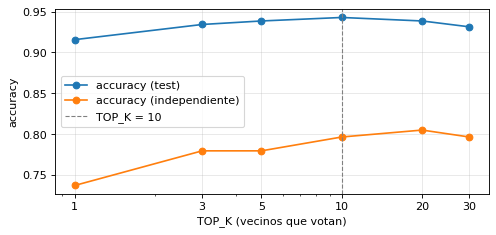

In [10]:
ks = (1, 3, 5, 10, 20, 30)
topk = pd.concat(
    {"test": R.top_k_sweep(sim_test, breeds[test_q], breeds[gallery], ks),
     "independiente": R.top_k_sweep(sim_ind, independent["breed"].to_numpy(), breeds[gallery], ks)}, axis=1)
display(topk.round(4))
fig, ax = plt.subplots(figsize=(7, 3))
for name in ("test", "independiente"):
    ax.plot(topk.index, topk[(name, "accuracy")], marker="o", label=f"accuracy ({name})")
ax.axvline(TOP_K, color="grey", ls="--", lw=1, label=f"TOP_K = {TOP_K}")
ax.set(xlabel="TOP_K (vecinos que votan)", ylabel="accuracy", xscale="log", xticks=ks, xticklabels=ks)
ax.legend()
plt.show()

**Lectura.**

- **Pocos vecinos votan peor**: con `TOP_K=1` la accuracy es 0,916 en `test` y 0,737 en el independiente; un vecino equivocado decide solo.
- **Con 10 se llega al máximo en `test`** (0,943) y casi al máximo en el independiente (0,797 contra 0,805 con 20, una imagen de 118 de diferencia, dentro del ruido). Con más vecinos la accuracy de `test` vuelve a bajar (0,931 con 30): entran vecinos de otras razas y el voto se diluye, como muestra la precision@k, que cae de 0,916 a 0,861.
- **Decisión**: `TOP_K=10`, el valor de la app, que además es el top-10 que muestra la pestaña de la Etapa 1.

### 5.4 Umbral de "unknown" (`SIMILARITY_THRESHOLD`)

La app responde "unknown" si el vecino más parecido queda por debajo del umbral. Calibrarlo exige consultas que
**deberían** rechazarse, y `valid` y `test` solo tienen razas conocidas. El criterio es el de class_4 6.14.7: se barre
el umbral sobre el score que decide la app (el mejor vecino de cada consulta), se mira la curva ROC y se elige el
punto de operación en una FAR objetivo (fracción de desconocidas aceptadas), sin tipear valores a mano. Desvío de
class_4: allá se calibra con pares genuino/impostor (verificación 1:1); acá la app identifica 1:N (como
`identify_face`), así que se calibra sobre el mejor vecino de cada consulta. `test` no se usa para calibrar.

**Qué es "desconocido".** Se probaron dos definiciones (D-12, D-26 y D-30 del plan):

1. **Razas que no están en la galería**: se apartan 7 razas (`calibration_breeds_v1.json`) y la galería de
   calibración es `train` de las otras 63. Conocidas: `valid` de las 63; desconocidas: `valid` y `train` de las 7.
2. **Imágenes sin perro** (la elegida): 117 imágenes de Wikimedia Commons con licencia libre (gatos, zorros,
   lobos, osos, ovejas, caballos, interiores, calles y jardines; `data/splits/calibration_negatives_v1.csv`),
   distintas de las 7 sin perro del conjunto independiente, que se usan para reportar. Galería: todo `train`.
   Conocidas: las 700 de `valid`.

**Cánidos salvajes.** El dataset trata a cuatro cánidos salvajes como razas (Dingo, Coyote, Dhole y African Wild
Dog), así que para este sistema un lobo o un zorro no es "lo que no es un perro": es un cánido parecido a clases
que conoce. Por eso el umbral se calibra con los negativos **sin lobos ni zorros** (D-30 del plan); los 25 cánidos
se siguen midiendo para documentar cuántos se aceptan. La decisión sale de cómo está definido el dataset, no de
los resultados del conjunto independiente, que se muestran después solo como consecuencia.

Mejor score de los negativos por grupo (la galeria es train):


notes,wolf,fox,bear,sheep,cattle,horse,rabbit,bedroom,cat,living_room,kitchen,garden,empty_street
size,16.000,9.000,10.000,11.000,1.000,7.000,5.000,12.000,5.000,8.000,1.000,18.000,14.000
min,0.798,0.772,0.745,0.734,0.755,0.697,0.634,0.654,0.667,0.646,0.673,0.620,0.630
median,0.863,0.851,0.772,0.762,0.755,0.725,0.703,0.679,0.678,0.674,0.673,0.654,0.647
max,0.939,0.914,0.795,0.818,0.755,0.807,0.727,0.710,0.775,0.708,0.673,0.691,0.690


,razas apartadas,"sin perro, todos","sin perro, sin canidos (elegida)"
n_known,630.0000,700.0000,700.0000
n_unknown,782.0000,117.0000,92.0000
threshold_env,0.9145,0.8912,0.8029
far_env,0.0499,0.0427,0.0326
tar_env,0.5651,0.8686,1.0000
eer,0.1749,0.0599,0.0007
eer_threshold,0.8973,0.8765,0.8345
auc,0.8832,0.9757,1.0000


Lobos y zorros aceptados con el umbral elegido: 88% de 25


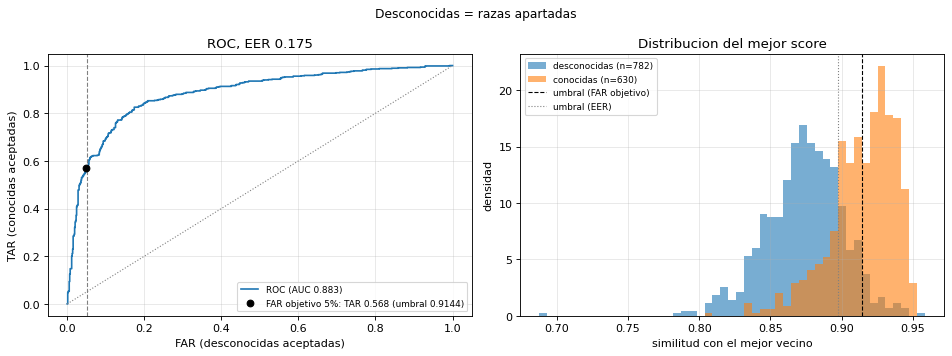

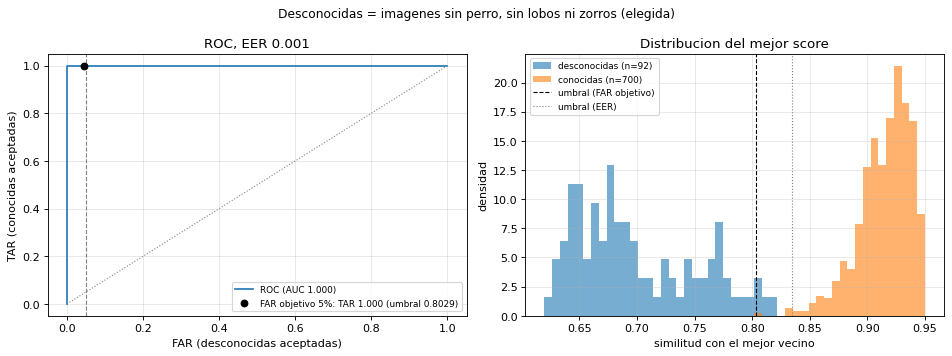

In [11]:
from lib.visualization.retrieval import plot_threshold_calibration

TARGET_FAR = 0.05
calibration_breeds = json.loads((settings.data_path / "splits" / "calibration_breeds_v1.json").read_text())
negatives = load_registry(settings.data_path / "splits" / "calibration_negatives_v1.csv")
NEGATIVES_ZIP = PERSIST / "calibration_negatives_v1.zip"
if not (DATASET / "calibration_negatives").exists() and IN_COLAB and NEGATIVES_ZIP.exists():
    shutil.unpack_archive(str(NEGATIVES_ZIP), str(DATASET))
raw_neg = R.load_or_compute_embeddings(
    STAGE1_DIR / "baseline_raw_negatives.npz", negatives["path"].tolist(), [DATASET / p for p in negatives["path"]], embed_raw)

# Definicion 1: razas apartadas (galeria de 63 razas).
masks = R.calibration_masks(manifest, calibration_breeds)
known63 = R.evaluate_queries(R.similarity_matrix(emb[masks["known"]], emb[masks["gallery"]], "cosine"),
                             breeds[masks["known"]], breeds[masks["gallery"]], ndcg_k=10, vote_k=TOP_K).per_query
held_out_best = R.similarity_matrix(emb[masks["unknown"]], emb[masks["gallery"]], "cosine").max(axis=1)
op_breeds = R.operating_point(known63["best_score"].to_numpy(), held_out_best, TARGET_FAR, known63["correct"].to_numpy())

# Definicion 2 (elegida): imagenes sin perro contra la galeria real (train, 70 razas).
valid_q = split == "valid"
known70 = R.evaluate_queries(R.similarity_matrix(emb[valid_q], emb[gallery], "cosine"),
                             breeds[valid_q], breeds[gallery], ndcg_k=10, vote_k=TOP_K).per_query
neg_best = R.similarity_matrix(R.l2_normalize(raw_neg), emb[gallery], "cosine").max(axis=1)
negatives["best_score"] = neg_best
CANIDS = {"wolf", "fox"}
canid = negatives["notes"].isin(CANIDS).to_numpy()
known_best70, known_ok70 = known70["best_score"].to_numpy(), known70["correct"].to_numpy()
op_all = R.operating_point(known_best70, neg_best, TARGET_FAR, known_ok70)
op_nodog = R.operating_point(known_best70, neg_best[~canid], TARGET_FAR, known_ok70)

print("Mejor score de los negativos por grupo (la galeria es train):")
display(negatives.groupby("notes")["best_score"].agg(["size", "min", "median", "max"]).sort_values("median", ascending=False).round(3).T)
keys = ("n_known", "n_unknown", "threshold_env", "far_env", "tar_env", "eer", "eer_threshold", "auc")
display(pd.DataFrame({
    "razas apartadas": {k: op_breeds[k] for k in keys},
    "sin perro, todos": {k: op_all[k] for k in keys},
    "sin perro, sin canidos (elegida)": {k: op_nodog[k] for k in keys},
}).round(4))
print(f"Lobos y zorros aceptados con el umbral elegido: {(neg_best[canid] >= op_nodog['threshold_env']).mean():.0%} de {canid.sum()}")
plot_threshold_calibration(op_breeds, known63["best_score"].to_numpy(), held_out_best, "Desconocidas = razas apartadas")
plt.show()
plot_threshold_calibration(op_nodog, known_best70, neg_best[~canid], "Desconocidas = imagenes sin perro, sin lobos ni zorros (elegida)")
plt.show()

In [12]:
# El umbral elegido sobre las consultas reportadas (galeria de 70 razas).
SIMILARITY_THRESHOLD = op_nodog["threshold_env"]
no_dog = registry[registry["scene"] == "no_dog"].reset_index(drop=True)
raw_no_dog = R.load_or_compute_embeddings(
    STAGE1_DIR / "baseline_raw_no_dog.npz", no_dog["path"].tolist(), [DATASET / p for p in no_dog["path"]], embed_raw)
no_dog_best = R.similarity_matrix(R.l2_normalize(raw_no_dog), emb[gallery], "cosine").max(axis=1)

rows = []
for name, t in (("sin umbral", None), ("razas apartadas, FAR 5 %", op_breeds["threshold_env"]),
                ("sin perro con canidos, FAR 5 %", op_all["threshold_env"]), ("sin perro sin canidos, FAR 5 % (elegido)", SIMILARITY_THRESHOLD)):
    for qname, sim, qb in (("test", sim_test, breeds[test_q]), ("independiente", sim_ind, independent["breed"].to_numpy())):
        s = R.evaluate_queries(sim, qb, breeds[gallery], ndcg_k=10, vote_k=TOP_K, threshold=t).summary(ci=False)
        rows.append({"umbral": name, "consultas": qname, "valor": t, "rechazadas": s["rejected"], "accuracy": s["accuracy"]})
    rows.append({"umbral": name, "consultas": "independiente sin perro (7)", "valor": t,
                 "rechazadas": float(np.mean(no_dog_best < (t if t is not None else -np.inf))), "accuracy": np.nan})
display(pd.DataFrame(rows).set_index(["umbral", "consultas"]).round(4))
print("Mejor score de las 7 imagenes sin perro del independiente:",
      dict(zip(no_dog["path"].str.rsplit("/", n=1).str[-1], no_dog_best.round(3))))

# Con vectores de norma 1 el umbral equivalente para SIMILARITY_METRIC=l2 es 1 / (1 + sqrt(2 - 2 cos)).
l2_equivalent = 1.0 / (1.0 + np.sqrt(2.0 - 2.0 * SIMILARITY_THRESHOLD))
print(f"SIMILARITY_THRESHOLD = {SIMILARITY_THRESHOLD:.4f} con cosine (equivalente con l2: {l2_equivalent:.4f})")

valor  rechazadas  accuracy
umbral                                   consultas                                                
sin umbral                               test                            NaN      0.0000    0.9429
                                         independiente                   NaN      0.0000    0.7966
                                         independiente sin perro (7)     NaN      0.0000       NaN
razas apartadas, FAR 5 %                 test                         0.9145      0.4500    0.5329
                                         independiente                0.9145      0.9322    0.0593
                                         independiente sin perro (7)  0.9145      1.0000       NaN
sin perro con canidos, FAR 5 %           test                         0.8912      0.1443    0.8229
                                         independiente                0.8912      0.6780    0.2966
                                         independiente sin perro (7)  0.8912      1.0000       NaN
sin perro sin canidos, FAR 5 % (elegido) test                         0.8029      0.0000    0.9429
                                         independiente                0.8029      0.0339    0.7797
                                         independiente sin perro (7)  0.8029      0.7143       NaN

Mejor score de las 7 imagenes sin perro del independiente: {'no_dog_01.jpg': np.float32(0.705), 'no_dog_02.jpg': np.float32(0.748), 'no_dog_03.jpg': np.float32(0.684), 'no_dog_04.jpg': np.float32(0.844), 'no_dog_05.jpg': np.float32(0.852), 'no_dog_06.jpg': np.float32(0.69), 'no_dog_07.jpg': np.float32(0.697)}
SIMILARITY_THRESHOLD = 0.8029 con cosine (equivalente con l2: 0.6143)


**Lectura.**

- **Razas apartadas: el rechazo a nivel raza no es viable.** Con FAR 5 % el umbral es 0,9145 y acepta solo el 56,5 % de las consultas conocidas (AUC 0,883, EER 0,175). Una raza que el modelo no vio sigue siendo un perro y su mejor vecino es casi tan parecido como el de una conocida: en `test` ese umbral rechazaría el 45 % de los perros y en el independiente el 93 %.
- **Sin perro, con todos los negativos: lo dominan los lobos y los zorros.** Sus scores (mediana 0,863 y 0,851) quedan al nivel de los perros, mientras que todos los demás grupos tienen como máximo 0,818. Con ellos, el umbral de FAR 5 % sube a 0,891, que rechaza el 14 % de `test` y el 68 % de las fotos reales.
- **Umbral elegido: 0,8029, sin lobos ni zorros (D-30).** Sobre `valid` acepta el 100 % de las consultas y el 3,3 % de los negativos (3 de 92); la separación es casi perfecta (AUC 1,000, EER 0,001). Consecuencia en las consultas reportadas: en `test` no rechaza ninguna (accuracy 0,943); en el independiente rechaza 4 de 118 fotos reales (accuracy 0,780 contra 0,797 sin umbral), y rechaza 5 de las 7 imágenes sin perro (los gatos, la calle y el living).
- **Limitación documentada**: acepta el 88 % de los lobos y zorros de calibración, y en el independiente acepta el zorro (0,844) y el lobo (0,852). Para este sistema son cánidos parecidos a clases del dataset (Dingo, Coyote, Dhole y African Wild Dog), y el detector de la Etapa 3 tampoco los separa (YOLO detecta al lobo como perro). Además el umbral se calibró con imágenes del dataset (`valid`) y 92 negativos: una FAR de 3 % se apoya en 3 imágenes, y en fotos reales los scores de los perros bajan, así que el margen es menor que en `valid`.
- **Valor para la app**: `SIMILARITY_THRESHOLD=0.8029` con `SIMILARITY_METRIC=cosine` (con `l2` el equivalente sería 0,6143).

## Experimentos: cómo se corren

Cada variante se entrena con `lib.training.trainer.train` (la misma función que usa `train_classifier`)
y guarda su checkpoint e historial en `output/experiments/`. Receta común (plan, D-23): AdamW,
scheduler coseno, label smoothing 0,1, weight decay 1e-4, batch 64, precisión mixta en GPU, early stopping
con paciencia 5 sobre la accuracy de `valid`, semilla 42. Se guarda la **mejor época según `valid`**, no la
última.

La selección (estrategia, hiperparámetros) se hace con `valid`. Una vez elegida la variante, el modelo
final se entrena con `classifier.train_classifier(config)`, que escribe el checkpoint que usa la app.

Presupuesto estimado en una T4: 15 a 25 s por época; unas 5 a 6 horas de época en total como máximo,
en la práctica menos por el early stopping.

In [13]:
from lib.training.trainer import TrainConfig, train
from lib.visualization.training import plot_confusion, plot_histories


def base_config(**overrides) -> TrainConfig:
    return TrainConfig(image_size=settings.image_size, num_workers=NUM_WORKERS, seed=SEED, **overrides)


def run_experiment(name: str, **overrides) -> dict:
    """Entrena una variante; si ya termino antes (archivo .done.json en Drive), reutiliza el resultado."""
    done = EXP_DIR / f"{name}.done.json"
    if done.exists():
        return json.loads(done.read_text())
    start = time.perf_counter()
    result = train(base_config(**overrides), manifest, DATASET, EXP_DIR / f"{name}.pth", EXP_DIR / f"{name}_history.json")
    history = load_history(name)
    summary = {
        "name": name,
        "best_val_accuracy": result.best_val_accuracy,
        "best_epoch": result.best_epoch,
        "epochs_run": result.epochs_run,
        "minutes": (time.perf_counter() - start) / 60,
        "trainable_parameters": history["trainable_parameters"],
        "overrides": overrides,
    }
    done.write_text(json.dumps(summary, indent=2))
    return summary


def load_history(name: str) -> dict:
    return json.loads((EXP_DIR / f"{name}_history.json").read_text())


def results_table(results: list[dict]) -> pd.DataFrame:
    table = pd.DataFrame(results).set_index("name")
    table["minutes"] = table["minutes"].round(1)
    return table[["best_val_accuracy", "best_epoch", "epochs_run", "minutes", "trainable_parameters"]].round(4)

## 6. Modelo A (obligatorio): fine-tuning de ResNet18

**Arquitectura.** ResNet18 preentrenada en ImageNet (`IMAGENET1K_V1`), con la capa `fc` reemplazada por
una cabeza lineal de 512 a 70 razas. El embedding para la búsqueda por similitud es la salida del
*global average pooling* (512 dimensiones), justo antes de la cabeza.

**Estrategias que se comparan** (transfer learning, plan D-21):

| Variante | Qué se entrena | LR | Idea |
|---|---|---|---|
| A1 feature extraction | solo la cabeza (backbone y sus BatchNorm congelados) | cabeza 1e-3 | ImageNet ya tiene ~118 razas de perro: las features genéricas deberían alcanzar bastante |
| A2 fine-tuning completo | todo | cabeza 1e-3, backbone 1e-4 | adapta también las capas profundas; LR menor en el backbone para no borrar lo preentrenado (olvido catastrófico) |
| A3 mejor de A1/A2 + pesos de clase | igual que la mejor | igual | `train` tiene de 65 a 198 imágenes por raza; pesos inversos a la frecuencia en la loss (D-25) |

En feature extraction los BatchNorm del backbone quedan en modo evaluación: si se dejaran en modo
entrenamiento cambiarían sus estadísticas aunque sus pesos estén congelados.

In [14]:
A_COMMON = dict(model="resnet18_finetuned")
results_a = [
    run_experiment("A1_feature_extraction", **A_COMMON, strategy="feature_extraction"),
    run_experiment("A2_finetune", **A_COMMON, strategy="finetune"),
]
best_strategy = max(results_a, key=lambda r: r["best_val_accuracy"])["overrides"]["strategy"]
results_a.append(run_experiment(f"A3_{best_strategy}_pesos_clase", **A_COMMON, strategy=best_strategy, class_weights=True))
display(results_table(results_a))

,best_val_accuracy,best_epoch,epochs_run,minutes,trainable_parameters
name,,,,,
A1_feature_extraction,0.9286,11,16,6.1,35910
A2_finetune,0.9386,9,14,6.2,11212422
A3_finetune_pesos_clase,0.9429,7,12,5.3,11212422


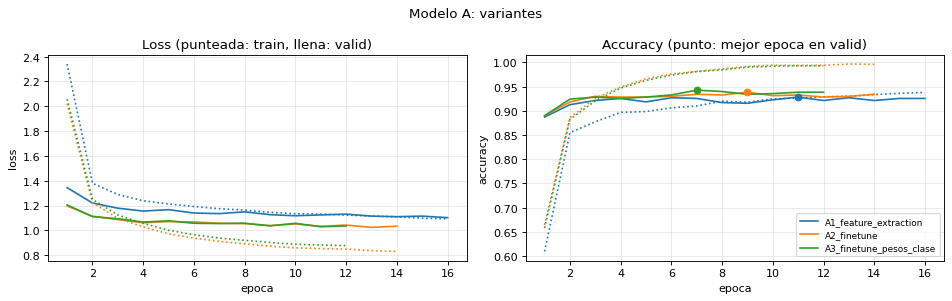

In [15]:
fig = plot_histories({r["name"]: load_history(r["name"]) for r in results_a}, title="Modelo A: variantes")
plt.show()

**Lectura** (corrida en Colab, T4, semilla 42).

| Variante | Mejor acc en `valid` | Mejor época | Épocas corridas | Minutos |
|---|---|---|---|---|
| A1 feature extraction | 0,9286 | 11 | 16 | 6,1 |
| A2 finetune | 0,9386 | 9 | 14 | 6,2 |
| A3 finetune + pesos de clase | **0,9429** | 7 | 12 | 5,3 |

- **El preentrenamiento hace casi todo el trabajo.** Con el backbone congelado y solo 35.910 parámetros
  entrenables (la cabeza lineal), A1 ya pasa el 0,88 en la primera época y llega a 0,93: las features
  de ImageNet separan bien las razas. Descongelar todo (A2, 11,2 M parámetros) suma un punto.
- **Las diferencias están dentro del ruido.** Con 700 imágenes de `valid` el error estándar de una
  accuracy cercana a 0,93 es de un punto, así que 1 a 1,5 puntos entre variantes no alcanzan para
  decir que una es mejor. Elegimos A3 porque es la mejor en `valid` y no cuesta más, no porque
  sepamos que los pesos de clase ayudan. Tiene sentido que su efecto sea chico: el desbalance de
  `train` es moderado (56 a 185 imágenes por raza) y `valid` está balanceado.
- **Sobreajuste.** En el finetune la accuracy de `train` llega a 0,98 o 0,99 mientras `valid` se
  queda en 0,94: memoriza `train` y por eso el early stopping corta pronto (épocas 12 a 14).
  En A1 la brecha es mucho menor porque la cabeza lineal tiene poca capacidad. La accuracy de
  `train` se mide con augmentation y label smoothing, así que la brecha es solo indicativa.

### Modelo A final

Se reentrena la variante ganadora con `train_classifier`, que guarda `models/resnet18_finetuned.pth` y
su historial (`resnet18_finetuned_history.json`). Recién ahí se evalúa sobre `test`.

In [16]:
from lib.bootstrap import build_classifier

classifier = build_classifier(settings)


def train_final(results: list[dict], **extra) -> dict:
    """Entrena el modelo final con la mejor variante (una sola vez: queda marcado en Drive)."""
    best = max(results, key=lambda r: r["best_val_accuracy"])
    config = base_config(**(best["overrides"] | extra))
    done = settings.model_path / f"{config.model}.done.json"
    if not done.exists():
        result = classifier.train_classifier(config)
        done.write_text(json.dumps({"from": best["name"], "best_val_accuracy": result.best_val_accuracy,
                                    "best_epoch": result.best_epoch, "config": asdict(config)}, indent=2, default=list))
    classifier.set_active_model(config.model)
    return json.loads(done.read_text())


final_a = train_final(results_a)
final_a

{'from': 'A3_finetune_pesos_clase',
 'best_val_accuracy': 0.9428571428571428,
 'best_epoch': 7,
 'config': {'model': 'resnet18_finetuned',
  'strategy': 'finetune',
  'epochs': None,
  'batch_size': 64,
  'lr_head': 0.001,
  'lr_backbone': 0.0001,
  'lr': 0.001,
  'weight_decay': 0.0001,
  'label_smoothing': 0.1,
  'patience': 5,
  'seed': 42,
  'num_workers': 2,
  'amp': True,
  'augment': True,
  'augmentation': None,
  'class_weights': True,
  'image_size': 224,
  'cnn_embedding_dim': 256,
  'cnn_dropout': 0.3,
  'cnn_batchnorm': True,
  'cnn_channels': [32, 64, 128, 256, 256],
  'cnn_train_stats': False,
  'pretrained': True,
  'max_per_class_train': None,
  'max_per_class_valid': None,
  'device': None}}

In [17]:
from lib.evaluation.classification import confusion_matrix, per_class_metrics, top_confused_pairs


def evaluate_final(name: str) -> tuple[dict, dict]:
    classifier.set_active_model(name)
    classifier.load_model(name).to(DEVICE)
    metrics = classifier.evaluate_classifier()  # test, metricas macro
    pred = classifier.predict_split("test")
    np.savez(EXP_DIR / f"test_predictions_{name}.npz", y_true=pred["y_true"], y_pred=pred["y_pred"], probs=pred["probs"])
    return metrics, pred


metrics_a, pred_a = evaluate_final("resnet18_finetuned")
pd.Series(metrics_a).round(4)

,0
accuracy,0.9243
precision,0.9333
recall,0.9243
specificity,0.9989
f1,0.9230


### Curvas de entrenamiento y matriz de confusión (Modelo A)

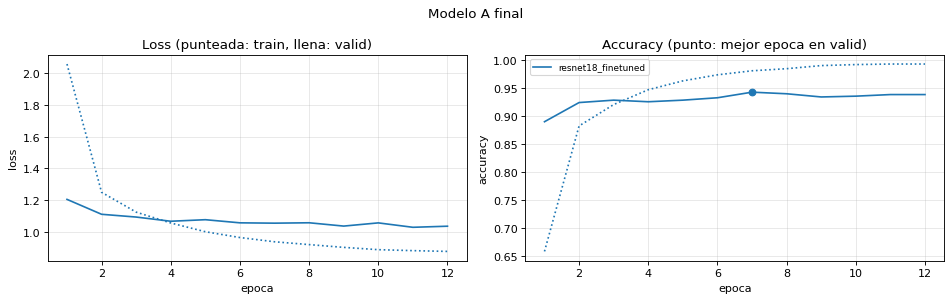

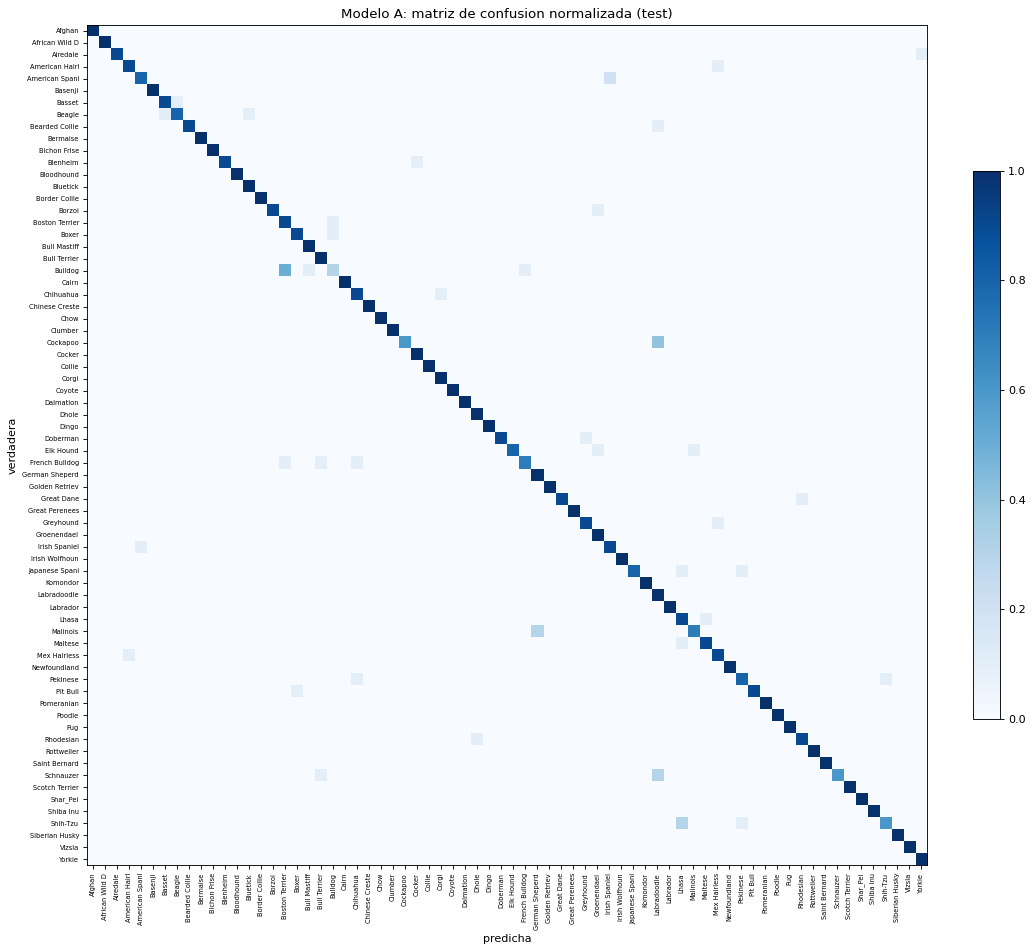

,breed_a,breed_b,a_as_b,b_as_a,errors
0,Boston Terrier,Bulldog,1,5,6
1,Cockapoo,Labradoodle,4,0,4
2,American Spaniel,Irish Spaniel,2,1,3
3,German Sheperd,Malinois,0,3,3
4,Labradoodle,Schnauzer,0,3,3
5,Lhasa,Shih-Tzu,0,3,3
6,American Hairless,Mex Hairless,1,1,2
7,Basset,Beagle,1,1,2
8,Lhasa,Maltese,1,1,2
9,Pekinese,Shih-Tzu,1,1,2


Razas con menor recall en test (n=10 por raza, descriptivo): {'Bulldog': 0.3, 'Cockapoo': 0.6, 'Schnauzer': 0.6, 'Shih-Tzu': 0.6, 'Malinois': 0.7, 'French Bulldog': 0.7, 'Beagle': 0.8, 'Elk Hound': 0.8}


In [18]:
plot_histories({"resnet18_finetuned": json.loads(classifier.history_path("resnet18_finetuned").read_text())},
               title="Modelo A final")
plt.show()


def confusion_report(pred: dict, title: str) -> None:
    cm = confusion_matrix(pred["y_true"], pred["y_pred"], len(pred["classes"]))
    plot_confusion(cm, pred["classes"], title=title)
    plt.show()
    display(pd.DataFrame(top_confused_pairs(cm, pred["classes"], k=10)))
    recall = pd.Series(per_class_metrics(cm)["recall"], index=pred["classes"]).sort_values()
    print("Razas con menor recall en test (n=10 por raza, descriptivo):", recall.head(8).round(2).to_dict())


confusion_report(pred_a, "Modelo A: matriz de confusion normalizada (test)")

**Lectura.** El modelo final (A3 reentrenado, mejor época 7) da en `test` accuracy 0,9243, precision
0,9333, recall 0,9243, especificidad 0,9989 y F1 0,9230. Queda unos dos puntos por debajo de su
mejor `valid` (0,9429). Es lo esperable: `valid` se usó para elegir la variante y la época, así que
su número es optimista. Por eso el resultado que se informa es el de `test`, medido una sola vez.

Los pares más confundidos en `test` son Boston Terrier y Bulldog (6 errores, casi todos de Bulldog
predicho como Boston Terrier), Cockapoo y Labradoodle (4), y Lhasa con Shih-Tzu y Pastor Alemán con
Malinois (3 cada uno). **Son los mismos pares que el EDA encontró en el espacio del baseline.**
Border Collie y Collie no aparecen entre los diez primeros. Si el baseline sin entrenar y el modelo
ajustado fallan en los mismos pares, el error viene sobre todo del parecido real entre las razas
(cruzas como Cockapoo y Labradoodle, o razas que se distinguen por el pelaje o el tamaño) y de
etiquetas dudosas, más que del modelo. La raza con menor recall es Bulldog (0,3) y le sigue Cockapoo
(0,6). Con 10 imágenes por raza en `test`, el recall por raza es descriptivo: un error mueve 10 puntos.

## 7. Modelo B (obligatorio): CNN propia

**Arquitectura** (`src/lib/models/cnn_custom.py`, plan D-22): 5 bloques conv 3x3, BatchNorm, ReLU y
max-pool 2x2 con 32, 64, 128, 256 y 256 canales; *global average pooling*; capa lineal de embedding
de 256 con ReLU; dropout 0,3; clasificador lineal de 70. Se entrena desde cero (inicialización de Kaiming).

- **Por qué así**: con ~100 imágenes por raza y sin preentrenamiento el riesgo principal es el
  sobreajuste. BatchNorm estabiliza y acelera el entrenamiento; GAP en vez de aplanar reduce mucho los
  parámetros (aplanar 256x7x7 a 256 serían 3,2 M solo en esa capa) y da algo de invariancia a la
  posición; el dropout regulariza la cabeza; la capa de embedding expone la representación para la
  búsqueda por similitud.
- LR 1e-3 con AdamW; hasta 60 épocas en el modelo final (desde cero tarda más en converger que el A).

In [19]:
from lib.models.cnn_custom import CustomCNN

cnn = CustomCNN(CLASSES)
shapes, x = [], torch.zeros(1, 3, settings.image_size, settings.image_size)
for name, block in [*(("bloque %d" % (i + 1), b) for i, b in enumerate(cnn.features)), ("gap", cnn.pool)]:
    x = block(x)
    shapes.append({"capa": name, "salida": tuple(x.shape[1:]), "parametros": sum(p.numel() for p in block.parameters())})
shapes.append({"capa": "embedding", "salida": (cnn.embedding_dim,), "parametros": sum(p.numel() for p in cnn.embedding.parameters())})
shapes.append({"capa": "clasificador", "salida": (cnn.num_classes,), "parametros": sum(p.numel() for p in cnn.classifier.parameters())})
arch = pd.DataFrame(shapes).set_index("capa")
display(arch)
print(f"Total: {sum(p.numel() for p in cnn.parameters()):,} parametros")

,salida,parametros
capa,,
bloque 1,"(32, 112, 112)",928
bloque 2,"(64, 56, 56)",18560
bloque 3,"(128, 28, 28)",73984
bloque 4,"(256, 14, 14)",295424
bloque 5,"(256, 7, 7)",590336
gap,"(256, 1, 1)",0
embedding,"(256,)",65792
clasificador,"(70,)",17990


Total: 1,063,014 parametros


**Tabla de experimentos** (hasta 30 épocas cada uno para entrar en el presupuesto; el final va a 60).
Cada variante cambia **una sola cosa** respecto de la base, para poder atribuirle el efecto:

| Variante | Cambio | Hipótesis |
|---|---|---|
| B1 base | — | referencia |
| B2 dropout 0,5 | más regularización en la cabeza | si B1 sobreajusta (train >> valid), debería ayudar |
| B3 augmentation fuerte | recortes de hasta 25 %, rotación de 20°, más brillo y contraste, más probables | más variedad simula más datos; si es excesiva, la red no llega a aprender (subajuste) |
| B4 estadísticas de `train` | la red re-normaliza la entrada con la media y el desvío de `train` | con BatchNorm después de la primera conv el efecto debería ser chico: la conv absorbe el cambio afín de la entrada |
| B5 sin BatchNorm | quita las capas BatchNorm | entrenamiento más lento e inestable desde cero; muestra para qué está BatchNorm |

**Por qué normalizar la entrada (contexto de B4).** Restar la media y dividir por el desvío de cada canal
deja los canales en escalas comparables (ninguno domina el gradiente) y el problema de optimización queda
mejor condicionado. Con un modelo preentrenado hay que usar las estadísticas con las que se entrenó: el
Modelo A las lee de los pesos de torchvision (`IMAGENET1K_V1.transforms()`) y verifica que coincidan con las
del preprocesamiento compartido; si no, el modelo no se construye. Entrenando desde cero, lo natural es
calcularlas sobre el propio `train`, que es lo que prueba B4 contra la base (ImageNet).

B4 no rompe el pipeline único: la imagen sigue llegando normalizada con ImageNet y la renormalización
vive dentro del modelo (buffers del checkpoint), así la app no cambia.

In [20]:
B_EPOCHS = 30
STRONG_AUG = dict(crop_border=0.25, crop_p=0.7, rotate_degrees=20.0, rotate_p=0.6, brightness=0.3, contrast=0.3, color_p=0.7)
B_COMMON = dict(model="cnn_custom", epochs=B_EPOCHS)
results_b = [
    run_experiment("B1_base", **B_COMMON),
    run_experiment("B2_dropout_0.5", **B_COMMON, cnn_dropout=0.5),
    run_experiment("B3_aug_fuerte", **B_COMMON, augmentation=STRONG_AUG),
    run_experiment("B4_stats_train", **B_COMMON, cnn_train_stats=True),
    run_experiment("B5_sin_batchnorm", **B_COMMON, cnn_batchnorm=False),
]
display(results_table(results_b))

,best_val_accuracy,best_epoch,epochs_run,minutes,trainable_parameters
name,,,,,
B1_base,0.5571,29,30,13.1,1063014
B2_dropout_0.5,0.4771,28,30,13.4,1063014
B3_aug_fuerte,0.4571,27,30,13.4,1063014
B4_stats_train,0.5529,28,30,13.8,1063014
B5_sin_batchnorm,0.5443,26,30,13.0,1062278


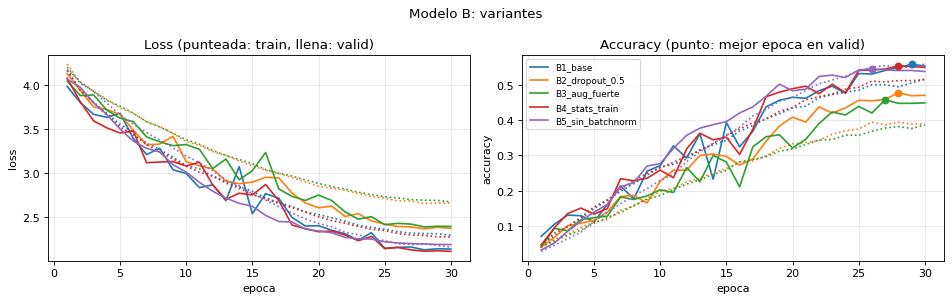

In [21]:
fig = plot_histories({r["name"]: load_history(r["name"]) for r in results_b}, title="Modelo B: variantes")
plt.show()

**Lectura.**

| Variante | Mejor acc en `valid` | Mejor época |
|---|---|---|
| B1 base | **0,5571** | 29 |
| B4 estadísticas de `train` | 0,5529 | 28 |
| B5 sin BatchNorm | 0,5443 | 26 |
| B2 dropout 0,5 | 0,4771 | 28 |
| B3 augmentation fuerte | 0,4571 | 27 |

- **Ninguna variante terminó de aprender en 30 épocas.** Todas tienen la mejor época al final, y
  las curvas de `valid` siguen subiendo. La comparación es entonces "con el mismo presupuesto", no
  "en convergencia", y eso condiciona cómo se lee cada hipótesis.
- **B2 y B3 empeoran porque el modelo subajusta, no porque sobreajuste.** La hipótesis de B2 pedía
  que B1 sobreajustara, y eso no pasa: la accuracy de `train` de B1 queda pegada a la de `valid`.
  Más dropout o más augmentation regularizan a un modelo que todavía no aprendió lo suficiente, y
  lo frenan: en B2 y B3 la accuracy de `train` (medida con dropout y augmentation) queda incluso
  por debajo de la de `valid`. Con más épocas la augmentation fuerte podría pagar, pero con este
  presupuesto no.
- **B4 confirma la teoría de la normalización de entrada.** Usar la media y el desvío de `train` en
  vez de los de ImageNet cambia 0,4 puntos, que es ruido: la BatchNorm después de la primera
  convolución ya re-centra y re-escala las activaciones, así que la red se adapta igual a cualquiera
  de las dos normalizaciones. Por eso el pipeline único con estadísticas de ImageNet no le cuesta
  nada al Modelo B.
- **B5 sin BatchNorm queda a un punto de B1.** Esperábamos que sin BatchNorm el entrenamiento fuera
  más lento e inestable. Con cinco bloques, inicialización de Kaiming y AdamW la red entrena igual, y
  la diferencia está dentro del ruido (error estándar de unos 1,9 puntos con accuracy de 0,55). Nos
  quedamos con BatchNorm porque no rinde peor y hace al modelo menos sensible a la escala de la entrada.
- Como era de esperar, el Modelo B queda muy por debajo del A: no tiene preentrenamiento y aprende
  todo de unas 7.200 imágenes.

La variante final es **B1**, reentrenada con un tope de 60 épocas, ya que la diferencia más clara es
que con 30 no le alcanzaba.

### Modelo B final

La mejor variante, con hasta 60 épocas, entrenada con `train_classifier` (`models/cnn_custom.pth`).

In [22]:
final_b = train_final(results_b, epochs=60)
metrics_b, pred_b = evaluate_final("cnn_custom")
pd.Series(metrics_b).round(4)

,0
accuracy,0.7029
precision,0.7213
recall,0.7029
specificity,0.9957
f1,0.6983


### Curvas de entrenamiento y matriz de confusión (Modelo B)

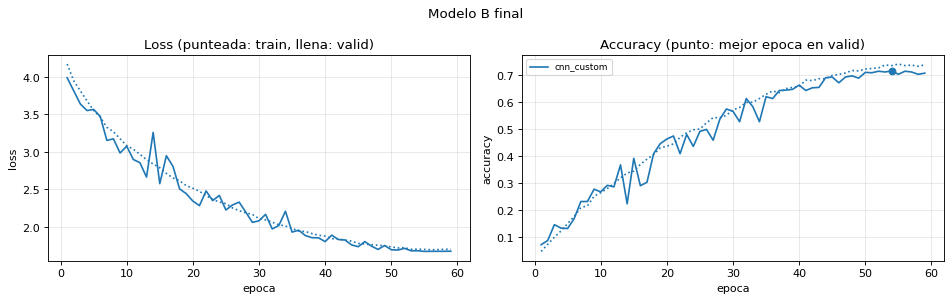

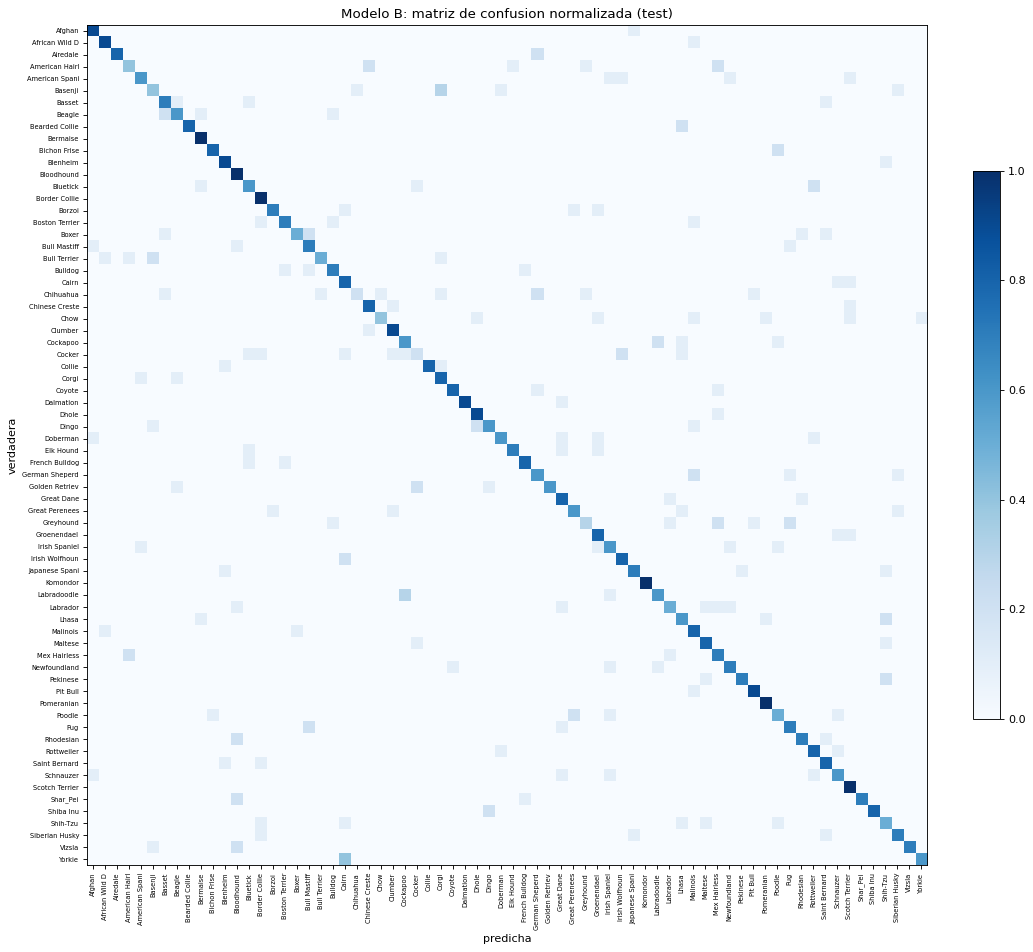

,breed_a,breed_b,a_as_b,b_as_a,errors
0,Cockapoo,Labradoodle,2,3,5
1,American Hairless,Mex Hairless,2,2,4
2,Cairn,Yorkie,0,4,4
3,Basenji,Corgi,3,0,3
4,Basset,Beagle,1,2,3
5,Bichon Frise,Poodle,2,1,3
6,Bull Mastiff,Pug,1,2,3
7,Lhasa,Shih-Tzu,2,1,3
8,African Wild Dog,Malinois,1,1,2
9,Airedale,German Sheperd,2,0,2


Razas con menor recall en test (n=10 por raza, descriptivo): {'Cocker': 0.2, 'Chihuahua': 0.2, 'Greyhound': 0.3, 'American Hairless': 0.4, 'Chow': 0.4, 'Basenji': 0.4, 'Bull Terrier': 0.5, 'Boxer': 0.5}


In [23]:
plot_histories({"cnn_custom": json.loads(classifier.history_path("cnn_custom").read_text())}, title="Modelo B final")
plt.show()
confusion_report(pred_b, "Modelo B: matriz de confusion normalizada (test)")

**Lectura.**

- **Más épocas era lo que faltaba.** Con un tope de 60, B1 llega a 0,7157 en `valid` en la época 54
  (contra 0,5571 con 30), y el early stopping corta en la 59.
- **El modelo sigue sin sobreajustar.** En la mejor época la accuracy de `train` es 0,735 y la de
  `valid` 0,716: está cerca de su límite de capacidad con estos datos, no memorizando.
- **Resultados en `test`:** accuracy 0,7029, precision 0,7213, recall 0,7029, especificidad 0,9957 y
  F1 0,6983. Igual que en el Modelo A, queda algo por debajo de `valid`.
- **Los errores están más repartidos que en el A.** La matriz de confusión tiene mucho más ruido
  fuera de la diagonal.
  - Siguen apareciendo pares del EDA, como Cockapoo con Labradoodle (5 errores, el primero) y Lhasa
    con Shih-Tzu.
  - Aparecen confusiones nuevas entre razas que no se parecen tanto: Cairn y Yorkie, Basenji y Corgi,
    Bull Mastiff y Pug.
  - La lectura es que el Modelo B se apoya en señales más gruesas, como el color, el pelaje o el
    tamaño aparente.
  - Las razas con menor recall son Cocker y Chihuahua (0,2 cada una).

## 8. Evaluación sobre el conjunto independiente

`test` sale del mismo dataset que `train`: imágenes de 224 px, con el perro centrado y ocupando casi
todo el cuadro. Por eso su accuracy mide la generalización **dentro de ese dominio**. El conjunto
independiente (`data/splits/independent_v1.csv`, armado en `1-pre-processing.ipynb`) son fotos reales
de otras fuentes: el perro ocupa una parte de la imagen, hay fondos, personas, otras resoluciones e
iluminaciones. La caída de accuracy entre `test` y el independiente es el **cambio de dominio**.

Para separar sus causas se clasifica cada imagen de dos formas:

- **Imagen completa**: el cambio de dominio "crudo", con el encuadre incluido.
- **Recorte de YOLO** (el de mayor confianza, como hace la Etapa 3): lo que ve de verdad la app.
  Si YOLO no encuentra el perro cuenta como error (la app no mostraría ninguna raza), y se informa
  aparte cuántas veces pasa.

La diferencia entre las dos mide cuánto de la caída explica el encuadre. Se usan solo las imágenes de
un perro; las escenas con varios perros y sin perros son para la detección (sección 12). Con unas pocas
imágenes por raza el intervalo de confianza es ancho y la tabla por raza es descriptiva.

In [24]:
from lib.dataset.independent import load_registry
from lib.dataset.torch_dataset import read_bgr
from lib.models.inference import predict_proba_fn
from lib.services.detection_service import DetectionService

independent = load_registry(settings.data_path / "splits" / "independent_v1.csv")
single = independent[independent["scene"] == "single"].reset_index(drop=True)
on_disk = single["path"].map(lambda p: (DATASET / p).exists())
print(f"{len(single)} imagenes de un perro en el registro ({single['breed'].nunique()} razas), {on_disk.sum()} en disco")
single = single[on_disk].reset_index(drop=True)

# Detector con la configuracion de la app (.env); la eleccion de sus valores esta en la seccion 12.
detector = DetectionService(classifier, settings.yolo_model, settings.yolo_conf_threshold,
                            settings.yolo_dog_class_id, min_confidence=0.0)
MODELS = {"Modelo A": "resnet18_finetuned", "Modelo B": "cnn_custom"}
predictors = {label: predict_proba_fn(classifier.load_model(name).to(DEVICE), settings.image_size)
              for label, name in MODELS.items()}

records = []
for row in single.itertuples():
    image = read_bgr(DATASET / row.path)
    detections = detector.detect_dogs(image)
    crop = None
    if detections:
        (x1, y1, x2, y2), _ = detections[0]
        crop = image[y1:y2, x1:x2]
    for label, predict in predictors.items():
        for mode, img in (("imagen completa", image), ("recorte YOLO", crop)):
            probs = predict([img])[0] if img is not None else None
            records.append({"path": row.path, "breed": row.breed, "modelo": label, "modo": mode,
                            "detectado": crop is not None,
                            "pred": CLASSES[int(probs.argmax())] if probs is not None else "sin deteccion",
                            "prob": float(probs.max()) if probs is not None else 0.0})
indep = pd.DataFrame(records)
indep["correct"] = indep["pred"] == indep["breed"]
missed = int((~indep.drop_duplicates("path")["detectado"]).sum())
print(f"YOLO no detecto ningun perro en {missed} de {len(single)} imagenes")

118 imagenes de un perro en el registro (20 razas), 118 en disco
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLO no detecto ningun perro en 12 de 118 imagenes


In [25]:
from lib.evaluation.classification import bootstrap_ci, classification_metrics, mcnemar_test

index = {b: i for i, b in enumerate(CLASSES)} | {"sin deteccion": len(CLASSES)}
rows = []
for (label, mode), group in indep.groupby(["modelo", "modo"], sort=False):
    metrics = classification_metrics(group["breed"].map(index).to_numpy(), group["pred"].map(index).to_numpy(), len(CLASSES) + 1)
    _, low, high = bootstrap_ci(group["correct"].to_numpy())
    rows.append({"modelo": label, "modo": mode, "imagenes": len(group), **{k: round(v, 4) for k, v in metrics.items()},
                 "accuracy IC95": f"[{low:.3f}, {high:.3f}]"})
for label, metrics in (("Modelo A", metrics_a), ("Modelo B", metrics_b)):
    rows.append({"modelo": label, "modo": "test (referencia)", "imagenes": 700, **{k: round(v, 4) for k, v in metrics.items()}})
display(pd.DataFrame(rows).set_index(["modelo", "modo"]))

for label in MODELS:
    pivot = indep[indep["modelo"] == label].pivot(index="path", columns="modo", values="correct")
    test = mcnemar_test(pivot["recorte YOLO"].to_numpy(), pivot["imagen completa"].to_numpy())
    print(f"{label}, recorte contra imagen completa: solo el recorte acierta {test['only_a']}, "
          f"solo la completa acierta {test['only_b']}, p = {test['p_value']:.3f}")

imagenes  accuracy  precision  recall  specificity      f1   accuracy IC95
modelo   modo                                                                                         
Modelo A imagen completa         118    0.5932     0.8103  0.5970       0.9880  0.6281  [0.508, 0.678]
         recorte YOLO            118    0.6441     0.8577  0.6360       0.9911  0.6884  [0.559, 0.729]
Modelo B imagen completa         118    0.1949     0.4042  0.2011       0.9871  0.2495  [0.127, 0.271]
         recorte YOLO            118    0.3559     0.5848  0.3549       0.9880  0.4283  [0.263, 0.441]
Modelo A test (referencia)       700    0.9243     0.9333  0.9243       0.9989  0.9230             NaN
Modelo B test (referencia)       700    0.7029     0.7213  0.7029       0.9957  0.6983             NaN

Modelo A, recorte contra imagen completa: solo el recorte acierta 20, solo la completa acierta 14, p = 0.392
Modelo B, recorte contra imagen completa: solo el recorte acierta 22, solo la completa acierta 3, p = 0.000


Accuracy por raza con el recorte de YOLO (descriptivo: pocas imagenes por raza)


modelo,Modelo A,Modelo B,n
breed,,,
Shih-Tzu,0.17,0.33,6
Cockapoo,0.20,0.40,5
Mex Hairless,0.33,0.17,6
Labradoodle,0.40,0.20,5
Poodle,0.40,0.00,5
Boston Terrier,0.50,0.33,6
Bulldog,0.50,0.50,6
French Bulldog,0.57,0.00,7
German Sheperd,0.60,0.40,5


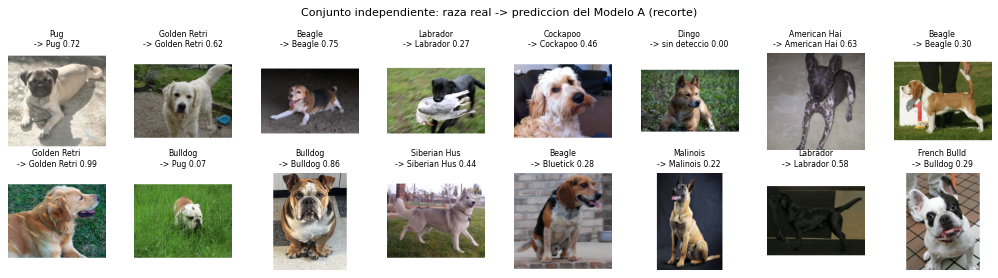

In [26]:
by_breed = (indep[indep["modo"] == "recorte YOLO"].pivot_table(index="breed", columns="modelo", values="correct", aggfunc="mean")
            .assign(n=single.groupby("breed").size()).sort_values("Modelo A"))
print("Accuracy por raza con el recorte de YOLO (descriptivo: pocas imagenes por raza)")
display(by_breed.round(2))

from lib.visualization.grid import show_grid

sample = indep[(indep["modelo"] == "Modelo A") & (indep["modo"] == "recorte YOLO")].sample(min(16, len(single)), random_state=SEED)
fig = show_grid([DATASET / p for p in sample["path"]],
                [f"{b[:12]}\n-> {p[:12]} {q:.2f}" for b, p, q in zip(sample["breed"], sample["pred"], sample["prob"])],
                cols=8, size=160, cell_inches=1.6, suptitle="Conjunto independiente: raza real -> prediccion del Modelo A (recorte)")
plt.show()

In [27]:
# Umbral de confianza del clasificador (calibrado en valid, seccion 12) sobre los recortes reales.
crops_a = indep[(indep["modelo"] == "Modelo A") & (indep["modo"] == "recorte YOLO")]
rows = []
for threshold in (0.0, 0.30, 0.50):
    accepted = crops_a["detectado"] & (crops_a["prob"] >= threshold)
    rows.append({"umbral": threshold, "cobertura": accepted.mean(),
                 "accuracy de lo aceptado": crops_a.loc[accepted, "correct"].mean(),
                 "aciertos sobre el total": (crops_a["correct"] & accepted).mean()})
print(f"Probabilidad mediana de los recortes: {crops_a.loc[crops_a['detectado'], 'prob'].median():.2f}")
display(pd.DataFrame(rows).set_index("umbral").round(3))

Probabilidad mediana de los recortes: 0.62


,cobertura,accuracy de lo aceptado,aciertos sobre el total
umbral,,,
0.0,0.898,0.717,0.644
0.3,0.729,0.756,0.551
0.5,0.568,0.851,0.483


**Lectura.**

| Modelo | Modo | accuracy | F1 | IC 95 % de la accuracy |
|---|---|---|---|---|
| A | imagen completa | 0,593 | 0,628 | [0,508; 0,678] |
| A | recorte YOLO | **0,644** | 0,688 | [0,559; 0,729] |
| B | imagen completa | 0,195 | 0,250 | [0,127; 0,271] |
| B | recorte YOLO | 0,356 | 0,428 | [0,263; 0,441] |
| A / B | `test` (referencia) | 0,924 / 0,703 | 0,923 / 0,698 | |

- **El cambio de dominio es grande.** El Modelo A pasa de 92,4 % en `test` a 64,4 % en fotos reales,
  aun con el recorte de YOLO; el B, de 70,3 % a 35,6 %. Son 118 imágenes, así que el intervalo es ancho
  (unos ±8 puntos), pero la caída es mucho mayor que esa incertidumbre.
- **El recorte ayuda, pero explica poco de la caída.** Al Modelo A recortar le suma 5 puntos y la
  diferencia no es significativa (McNemar: 20 imágenes que solo acierta el recorte contra 14, p = 0,39).
  Al Modelo B le suma 16 puntos (22 contra 3, p < 0,001): una red sin preentrenamiento depende más de
  ver al perro ocupando todo el cuadro, como en `train`. Además YOLO no encuentra el perro en 12 de las
  118 fotos (10 %), y esas cuentan como error.
- **Lo que queda es el dominio en sí.** Con el perro ya recortado siguen cambiando la iluminación, la
  resolución, la pose y el estilo de las fotos (las de `train` son recortes chicos y centrados, las del
  independiente son fotos de Wikimedia de todo tipo).
- **Las peores razas son los pares que se confunden**, que el conjunto independiente incluyó a
  propósito: Shih-Tzu (1 de 6), Cockapoo (1 de 5), Labradoodle (2 de 5), Boston Terrier y Bulldog (3 de
  6) y Bulldog Francés (4 de 7). Fuera de los pares, fallan razas con mucha variación de pelaje o de corte
  como Mexican Hairless (2 de 6) y Poodle (2 de 5). Con 5 a 8 fotos por raza es descriptivo.
- **El umbral de confianza calibrado en `valid` no se transfiere.** En `test`, con 0,30 el Modelo A
  respondía el 96 % con 94,8 % de acierto. Sobre los recortes reales la confianza es mucho más baja
  (mediana de 0,62), así que con 0,30 responde solo el 73 % y acierta el 76 % de lo que responde:
  lejos del 95 %. Es el caso del que advierte Guo et al.: la confianza de la red está calibrada para su
  propio dominio. El umbral igual mejora lo que se muestra (de 72 % a 76 % de acierto en lo aceptado), y
  se mantiene en 0,30 porque calibrarlo con este conjunto sería elegirlo sobre los mismos datos en que
  se reporta.
- **Conclusión para la app:** en fotos reales hay que esperar del orden de dos de cada tres razas
  correctas, no nueve de cada diez. Las mejoras posibles serían entrenar con augmentations más parecidas
  a fotos reales o sumar imágenes de otras fuentes a `train`.

## 9. Embeddings de los modelos entrenados

Los modelos de la Etapa 2 también sirven para la búsqueda por similitud de la Etapa 1: su penúltima
capa es un embedding (512 dimensiones en el Modelo A, 256 en el B), que la app usa cuando
`EMBEDDING_MODEL` no es `baseline` (`extract_custom_embedding`). La pregunta es si entrenar para
clasificar razas mejora el espacio de embeddings para buscar razas.

**Qué se espera.** La pérdida de clasificación empuja a que las imágenes de una raza queden del mismo lado
de la frontera lineal de la cabeza, no necesariamente juntas: la entropía cruzada separa por *dirección*
y no penaliza que una raza esté dispersa. Aun así, en la práctica las clases quedan agrupadas, y como
los vectores se normalizan en L2 la similitud coseno compara justamente direcciones. El baseline
(ResNet50 de ImageNet, sin ajustar) tiene un backbone más grande y ya vio 118 razas de perro en ImageNet.

Mismo protocolo que la sección 5: galería = `train`, consultas = `test`, coseno, NDCG@10 con
`n_relevant` = imágenes de la raza en la galería, raza por voto de los 10 vecinos y sin umbral. Se suma
el **coeficiente de silueta** (coseno) de los embeddings de `test`: para cada imagen compara la distancia
media a su raza con la de la raza vecina más cercana; va de -1 a 1 y mide cuán compactas y separadas
quedan las razas, sin depender de la galería.

In [28]:
from sklearn.metrics import silhouette_score

from lib.evaluation.retrieval import evaluate_queries, load_or_compute_embeddings, per_breed_table, similarity_matrix
from lib.models.baseline import BaselineEmbedder
from lib.models.inference import embed_batch_fn

gallery = manifest[manifest["split"] == "train"].reset_index(drop=True)
queries = manifest[manifest["split"] == "test"].reset_index(drop=True)
EMB_DIR = EXP_DIR / "embeddings"


def split_embeddings(key: str, embed_batch) -> dict[str, np.ndarray]:
    return {split: load_or_compute_embeddings(EMB_DIR / f"{key}_{split}.npz", rows["path"].tolist(),
                                              [DATASET / p for p in rows["path"]], embed_batch)
            for split, rows in (("train", gallery), ("test", queries))}


EMBEDDERS = {
    "baseline (ResNet50 ImageNet)": ("baseline", lambda: BaselineEmbedder(settings.image_size, DEVICE).embed_batch),
    "Modelo A (ResNet18 fine-tuned)": ("resnet18_finetuned", lambda: embed_batch_fn(classifier.load_model("resnet18_finetuned").to(DEVICE), settings.image_size)),
    "Modelo B (CNN propia)": ("cnn_custom", lambda: embed_batch_fn(classifier.load_model("cnn_custom").to(DEVICE), settings.image_size)),
}
embeddings, retrieval_eval, rows = {}, {}, []
for label, (key, make) in EMBEDDERS.items():
    emb = embeddings[label] = split_embeddings(key, make())
    evaluation = retrieval_eval[label] = evaluate_queries(similarity_matrix(emb["test"], emb["train"], "cosine"),
                                                          queries["breed"], gallery["breed"])
    summary = evaluation.summary()
    rows.append({"embeddings": label, "dimension": emb["train"].shape[1],
                 **{k: round(v, 4) for k, v in summary.items() if k not in ("n", "rejected")},
                 "silueta (test)": round(float(silhouette_score(emb["test"], queries["breed"], metric="cosine")), 4)})
emb_table = pd.DataFrame(rows).set_index("embeddings")
display(emb_table)

,dimension,ndcg@10,ndcg@10_low,ndcg@10_high,precision@10,precision@10_low,precision@10_high,accuracy,accuracy_low,accuracy_high,silueta (test)
embeddings,,,,,,,,,,,
baseline (ResNet50 ImageNet),2048,0.9016,0.8865,0.9167,0.8964,0.8811,0.9119,0.9429,0.9243,0.9600,0.2969
Modelo A (ResNet18 fine-tuned),512,0.9185,0.9022,0.9335,0.9183,0.9024,0.9330,0.9400,0.9229,0.9571,0.3032
Modelo B (CNN propia),256,0.5961,0.5704,0.6234,0.5854,0.5601,0.6123,0.7043,0.6700,0.7386,0.0596


In [29]:
# Comparacion pareada con el baseline: las mismas 700 consultas, asi que se compara consulta a consulta.
from lib.evaluation.classification import mcnemar_test

base = retrieval_eval["baseline (ResNet50 ImageNet)"].per_query
rng = np.random.default_rng(SEED)
rows = []
for label in list(EMBEDDERS)[1:]:
    other = retrieval_eval[label].per_query
    diff = (other["ndcg"] - base["ndcg"]).to_numpy()
    boot = diff[rng.integers(0, len(diff), size=(2000, len(diff)))].mean(axis=1)
    test = mcnemar_test(other["correct"].to_numpy(), base["correct"].to_numpy())
    rows.append({"embeddings": label, "NDCG@10 menos baseline": round(diff.mean(), 4),
                 "IC95": f"[{np.quantile(boot, 0.025):.4f}, {np.quantile(boot, 0.975):.4f}]",
                 "accuracy: solo este acierta": test["only_a"], "solo el baseline acierta": test["only_b"],
                 "McNemar p": round(test["p_value"], 4)})
display(pd.DataFrame(rows).set_index("embeddings"))

,NDCG@10 menos baseline,IC95,accuracy: solo este acierta,solo el baseline acierta,McNemar p
embeddings,,,,,
Modelo A (ResNet18 fine-tuned),0.0169,"[0.0039, 0.0296]",19,21,0.8746
Modelo B (CNN propia),-0.3055,"[-0.3320, -0.2785]",13,180,0.0000


In [30]:
# Las mismas galerias con consultas del conjunto independiente (fotos reales, seccion 8).
indep_queries = independent[(independent["scene"] == "single") & independent["path"].map(lambda p: (DATASET / p).exists())].reset_index(drop=True)
indep_images = [read_bgr(DATASET / p) for p in indep_queries["path"]]
indep_eval, rows = {}, []
for label, (key, make) in EMBEDDERS.items():
    embed = make()
    q = np.concatenate([embed(indep_images[i:i + 16]) for i in range(0, len(indep_images), 16)])
    evaluation = indep_eval[label] = evaluate_queries(similarity_matrix(q, embeddings[label]["train"], "cosine"),
                                                      indep_queries["breed"], gallery["breed"])
    summary = evaluation.summary()
    rows.append({"embeddings": label, **{k: round(v, 4) for k, v in summary.items() if k in
                 ("ndcg@10", "ndcg@10_low", "ndcg@10_high", "accuracy", "accuracy_low", "accuracy_high")}})
display(pd.DataFrame(rows).set_index("embeddings"))
test = mcnemar_test(indep_eval["baseline (ResNet50 ImageNet)"].per_query["correct"].to_numpy(),
                    indep_eval["Modelo A (ResNet18 fine-tuned)"].per_query["correct"].to_numpy())
print(f"Independiente, baseline contra Modelo A: solo el baseline acierta {test['only_a']}, "
      f"solo el A acierta {test['only_b']}, p = {test['p_value']:.1e}")

,ndcg@10,ndcg@10_low,ndcg@10_high,accuracy,accuracy_low,accuracy_high
embeddings,,,,,,
baseline (ResNet50 ImageNet),0.7162,0.6615,0.7723,0.7966,0.7203,0.8644
Modelo A (ResNet18 fine-tuned),0.5854,0.5146,0.6592,0.5847,0.5000,0.6695
Modelo B (CNN propia),0.1869,0.1492,0.2300,0.2458,0.1780,0.3305


Independiente, baseline contra Modelo A: solo el baseline acierta 30, solo el A acierta 5, p = 2.2e-05


In [31]:
worst = pd.concat({label: per_breed_table(ev.per_query)["ndcg"] for label, ev in retrieval_eval.items()}, axis=1)
print("NDCG@10 por raza: las 10 peores con el Modelo A (descriptivo, 10 consultas por raza)")
display(worst.sort_values("Modelo A (ResNet18 fine-tuned)").head(10).round(3))

NDCG@10 por raza: las 10 peores con el Modelo A (descriptivo, 10 consultas por raza)


,baseline (ResNet50 ImageNet),Modelo A (ResNet18 fine-tuned),Modelo B (CNN propia)
raza,,,
Bulldog,0.417,0.577,0.446
Malinois,0.797,0.629,0.576
Shih-Tzu,0.664,0.700,0.453
Schnauzer,0.910,0.713,0.435
Greyhound,0.803,0.727,0.202
Labradoodle,0.718,0.733,0.458
Cockapoo,0.571,0.754,0.507
American Hairless,0.600,0.781,0.342
Lhasa,0.605,0.784,0.433


**Visualización.** t-SNE de los embeddings de `test` de 12 razas: los pares que más se confunden y
algunas razas bien distintas. Siguiendo class_4 (6.14.3), primero PCA a 50 dimensiones (quita ruido
y acelera) y después t-SNE a 2. t-SNE conserva vecindarios, no distancias globales: la separación entre
grupos lejanos y el tamaño de cada grupo no se interpretan, sí qué razas quedan mezcladas.

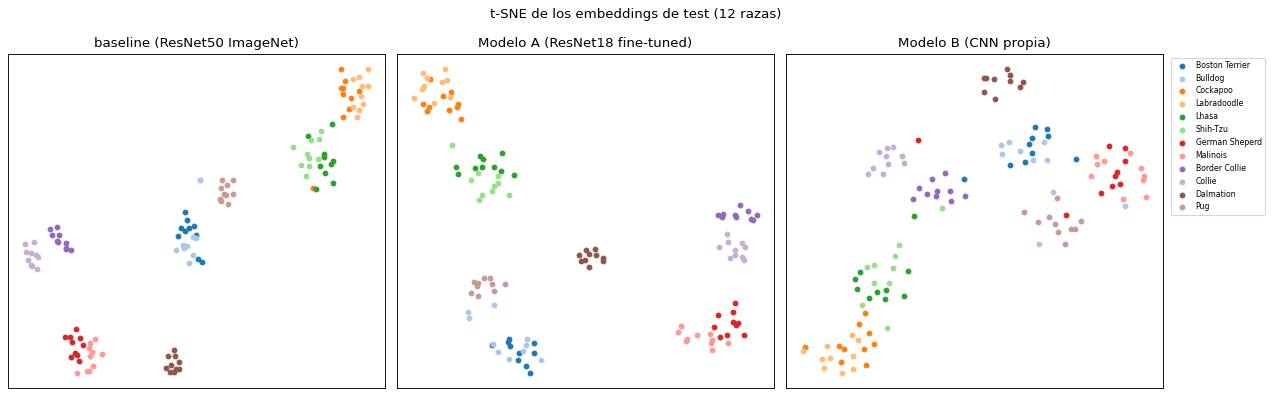

In [32]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

SHOWN = ["Boston Terrier", "Bulldog", "Cockapoo", "Labradoodle", "Lhasa", "Shih-Tzu",
         "German Sheperd", "Malinois", "Border Collie", "Collie", "Dalmation", "Pug"]
mask = queries["breed"].isin(SHOWN).to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (label, emb) in zip(axes, embeddings.items()):
    x = emb["test"][mask]
    x = PCA(n_components=min(50, x.shape[1]), random_state=SEED).fit_transform(x)
    xy = TSNE(n_components=2, perplexity=20, init="pca", max_iter=1000, random_state=SEED).fit_transform(x)
    for k, breed in enumerate(SHOWN):
        sel = queries["breed"].to_numpy()[mask] == breed
        ax.scatter(xy[sel, 0], xy[sel, 1], s=18, color=plt.cm.tab20(k), label=breed)
    ax.set(title=label, xticks=[], yticks=[])
axes[-1].legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.suptitle("t-SNE de los embeddings de test (12 razas)")
fig.tight_layout()
plt.show()

**Lectura** (corrida local en CPU; los embeddings no dependen del dispositivo).

| Embeddings | Dimensión | NDCG@10 | precision@10 | accuracy por vecinos | Silueta (test) |
|---|---|---|---|---|---|
| baseline (ResNet50 ImageNet) | 2048 | 0,902 [0,887; 0,917] | 0,896 | 0,943 [0,924; 0,960] | 0,297 |
| Modelo A (ResNet18 fine-tuned) | 512 | **0,919** [0,902; 0,934] | 0,918 | 0,940 [0,923; 0,957] | 0,303 |
| Modelo B (CNN propia) | 256 | 0,596 [0,570; 0,623] | 0,585 | 0,704 [0,670; 0,739] | 0,060 |

- **El Modelo A ordena mejor a los vecinos que el baseline, con un vector cuatro veces más chico.**
  Comparando consulta a consulta, su NDCG@10 es 0,017 más alto (IC 95 % [0,004; 0,030]): la mejora es
  chica pero no es ruido. En cambio, la raza votada por los 10 vecinos acierta lo mismo (McNemar: 19
  consultas que solo acierta A y 21 que solo acierta el baseline, p = 0,87). Es decir: el fine-tuning
  sube más vecinos correctos al principio de la lista, pero el voto ya acertaba igual con el baseline.
- **Pero afuera del dataset es al revés, y por mucho.** Con las 118 fotos reales del conjunto
  independiente como consultas (misma galería), el baseline acierta 0,797 [0,720; 0,864] y el Modelo A
  0,585 [0,500; 0,669], con NDCG@10 de 0,716 contra 0,585. McNemar: 30 fotos que solo acierta el
  baseline contra 5 que solo acierta el A (p = 2e-5). El B cae a 0,246. El fine-tuning especializó el
  espacio de embeddings en el estilo del dataset (perro centrado y llenando el cuadro): gana un poco en
  `test`, que es del mismo estilo, y pierde mucho en fotos reales. El baseline nunca vio este dataset y
  sus rasgos generales de ImageNet se transfieren mejor. Es el mismo cambio de dominio de la sección 8.
- **El fine-tuning reordena el espacio donde más se necesitaba.** Mejoran las razas que el baseline
  confundía: Bulldog (NDCG 0,42 a 0,58), Cockapoo (0,57 a 0,75), Lhasa (0,61 a 0,78) y Boston Terrier
  (0,62 a 0,80). A cambio empeoran algunas que el baseline resolvía bien, como Malinois (0,80 a 0,63) y
  Schnauzer (0,91 a 0,71). Con 10 consultas por raza esto es descriptivo.
- **El Modelo B casi no agrupa las razas.** La silueta de 0,06 indica razas muy mezcladas (la del
  baseline y la del A, alrededor de 0,30, es baja en valor absoluto, como es habitual con 70 clases en
  cientos de dimensiones, pero cinco veces mayor). Su accuracy por vecinos (0,704) es la misma que la de
  su clasificador (0,703): el embedding sabe lo mismo que la cabeza, que es poco.
- **t-SNE.** En los tres modelos los pares parecidos quedan uno al lado del otro: Cockapoo y Labradoodle,
  Lhasa y Shih-Tzu, Pastor Alemán y Malinois, Boston Terrier y Bulldog. Lo que cambia es la mezcla: en el
  baseline y en el A cada par forma un grupo compacto y casi sin intrusos de otras razas, y en el B los
  grupos se estiran y se tocan con razas que no se parecen.

## 10. Análisis de errores

Sobre `test` y con el Modelo A (el que usa la app). En multiclase, un error es a la vez un **falso
negativo** de la raza real (no la reconoció) y un **falso positivo** de la raza predicha (la nombró sin
que estuviera). Se miran tres cosas:

1. **Errores con alta confianza**: los más peligrosos, porque ningún umbral de confianza los filtra.
2. **Las razas con peor F1** en los dos modelos.
3. **Grad-CAM** (propio, `lib/evaluation/gradcam.py`, D-10) para ver en qué zona de la imagen se apoya cada
   modelo: si mira al perro o al fondo. Grad-CAM pondera cada mapa de la última capa convolucional por el
   promedio de los gradientes del logit de la clase, suma y aplica ReLU; el resultado se reescala a la
   imagen. Se muestra sobre lo que ve el modelo (la imagen con el padding del preprocesamiento).

53 errores del Modelo A en test; con probabilidad >= 0.5: 18


,path,real,predicha,prob predicha,prob real
262,test/Cockapoo/08.jpg,Cockapoo,Labradoodle,0.963,0.004
363,test/French Bulldog/04.jpg,French Bulldog,Boston Terrier,0.865,0.067
207,test/Bulldog/10.jpg,Bulldog,Boston Terrier,0.827,0.041
625,train/Schnauzer/042.jpg,Schnauzer,Labradoodle,0.817,0.032
268,train/Cockapoo/060.jpg,Cockapoo,Labradoodle,0.727,0.169
200,test/Bulldog/01.jpg,Bulldog,French Bulldog,0.702,0.013
164,test/Boston Terrier/06.jpg,Boston Terrier,Bulldog,0.665,0.227
39,train/American Hairless/50.jpg,American Hairless,Mex Hairless,0.634,0.287
504,test/Malinois/06.jpg,Malinois,German Sheperd,0.624,0.326
208,train/Bulldog/006.jpg,Bulldog,Bull Mastiff,0.618,0.115


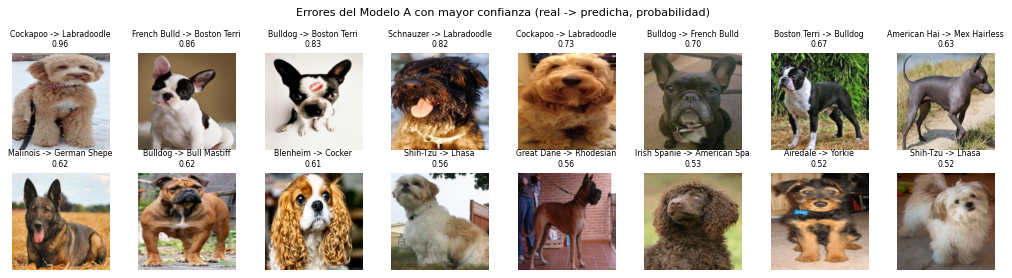

In [33]:
from lib.dataset.torch_dataset import read_bgr
from lib.visualization.grid import show_grid

MODELS = {"Modelo A": "resnet18_finetuned", "Modelo B": "cnn_custom"}
probs_a = pred_a["probs"]
errors = pd.DataFrame({
    "path": pred_a["rows"]["path"].to_numpy(),
    "real": np.array(CLASSES)[pred_a["y_true"]], "predicha": np.array(CLASSES)[pred_a["y_pred"]],
    "prob predicha": probs_a.max(axis=1), "prob real": probs_a[np.arange(len(probs_a)), pred_a["y_true"]],
})
errors = errors[errors["real"] != errors["predicha"]].sort_values("prob predicha", ascending=False)
print(f"{len(errors)} errores del Modelo A en test; con probabilidad >= 0.5: {(errors['prob predicha'] >= 0.5).sum()}")
display(errors.head(12).round(3))
fig = show_grid([DATASET / p for p in errors["path"].head(16)],
                [f"{r[:12]} -> {p[:12]}\n{q:.2f}" for r, p, q in zip(errors["real"], errors["predicha"], errors["prob predicha"])][:16],
                cols=8, size=160, cell_inches=1.6, suptitle="Errores del Modelo A con mayor confianza (real -> predicha, probabilidad)")
plt.show()

In [34]:
f1 = pd.DataFrame({label: per_class_metrics(confusion_matrix(p["y_true"], p["y_pred"], len(CLASSES)))["f1"]
                   for label, p in (("Modelo A", pred_a), ("Modelo B", pred_b))}, index=CLASSES)
print("Razas con menor F1 en test (10 imagenes por raza: descriptivo)")
display(f1.sort_values("Modelo A").head(8).round(2))
display(f1.sort_values("Modelo B").head(8).round(2))

Razas con menor F1 en test (10 imagenes por raza: descriptivo)


,Modelo A,Modelo B
Bulldog,0.40,0.70
Shih-Tzu,0.71,0.45
Labradoodle,0.71,0.63
Boston Terrier,0.72,0.74
Schnauzer,0.75,0.60
Cockapoo,0.75,0.60
Lhasa,0.75,0.55
French Bulldog,0.78,0.80


,Modelo A,Modelo B
Cocker,0.95,0.25
Chihuahua,0.86,0.31
Greyhound,0.90,0.40
Basenji,1.00,0.44
Shih-Tzu,0.71,0.45
American Hairless,0.90,0.47
Poodle,1.00,0.50
Chow,1.00,0.53


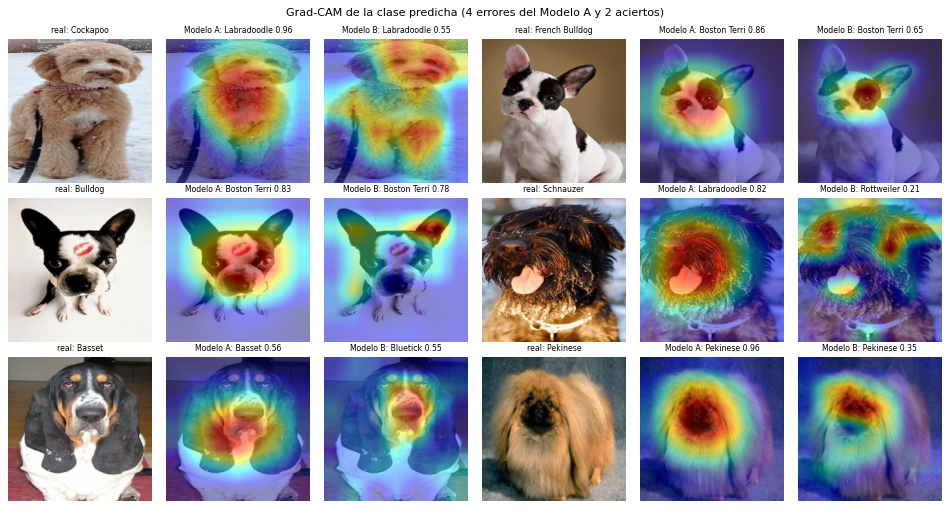

In [35]:
from lib.evaluation.gradcam import GradCAM
from lib.visualization.explain import model_input_rgb, overlay_heatmap
from lib.vision.preprocessing import preprocess_to_tensor

hits = np.flatnonzero(pred_a["y_true"] == pred_a["y_pred"])
examples = list(errors["path"].head(4)) + list(pred_a["rows"]["path"].to_numpy()[np.random.default_rng(SEED).choice(hits, 2, replace=False)])

panels, titles = [], []
for path in examples:
    image = read_bgr(DATASET / path)
    base = model_input_rgb(image, settings.image_size)
    x = preprocess_to_tensor(image, settings.image_size).unsqueeze(0)
    true_breed = queries.loc[queries["path"] == path, "breed"].iloc[0]
    panels.append(base); titles.append(f"real: {true_breed[:14]}")
    for label, name in MODELS.items():
        with GradCAM(classifier.load_model(name)) as cam:
            heatmap, index, prob = cam(x)
        panels.append(overlay_heatmap(base, heatmap)); titles.append(f"{label}: {CLASSES[index][:12]} {prob:.2f}")
fig = show_grid(panels, titles, cols=6, size=224, cell_inches=2.0,
                suptitle="Grad-CAM de la clase predicha (4 errores del Modelo A y 2 aciertos)")
plt.show()

**Lectura.**

- **Los errores del Modelo A son casi todos entre razas parecidas.** De los 53 errores en `test`, los de
  mayor confianza son Cockapoo con Labradoodle, Bulldog con Bulldog Francés y Boston Terrier, Shih-Tzu con
  Lhasa, Malinois con Pastor Alemán y los dos perros sin pelo (American y Mexican Hairless): los mismos
  pares del EDA y de la sección 6.
- **18 de los 53 errores tienen probabilidad de 0,5 o más.** Ningún umbral razonable de confianza los
  filtra (sección 12): el modelo está seguro y se equivoca.
- **Parte de los errores son de etiqueta, no del modelo.** A simple vista, la imagen etiquetada Bulldog que
  el modelo llama Boston Terrier con 0,83 tiene la cara y las orejas de un Boston Terrier, y la que llama
  Bulldog Francés con 0,70 tiene las orejas de murciélago del Francés. Es una hipótesis (no somos
  expertos en razas), pero explicaría por qué Bulldog es la raza con peor F1 (0,40): un modelo no puede
  acertar una etiqueta equivocada.
- **Grad-CAM: los dos modelos miran al perro, no al fondo.** En los seis ejemplos el mapa del Modelo A se
  concentra en la cabeza (ojos, hocico, orejas), que es donde están los rasgos de raza; el del Modelo B es
  más difuso y en el Schnauzer se reparte por el pelaje y el borde de la imagen, con una predicción de
  0,21. En estos casos el error no viene de un atajo con el fondo sino del parecido real entre razas. Son
  seis ejemplos: es una ilustración, no una prueba.
- **Las peores razas del Modelo B son otras:** Cocker (F1 0,25), Chihuahua (0,31), Greyhound (0,40) y
  Basenji (0,44), que el Modelo A resuelve con 0,86 o más. Son razas con mucha variación interna (colores,
  pelo largo o corto, poses), y una red sin preentrenamiento que vio unas 100 fotos por raza se apoya en
  señales gruesas como el color o la silueta.

## 11. Costo computacional

Lo que cuesta cada modelo en la app: parámetros, tamaño del archivo, dimensión del embedding y latencia
por imagen **en CPU** (donde corre la app en Docker), con una imagen por llamada como en un request.
Se toman 5 llamadas de calentamiento y la mediana de 30.

Se compara además el `.pth` (lo que se entrega, D-09) con el mismo modelo exportado a **ONNX** y corrido
con onnxruntime, que aplica optimizaciones de grafo (fusiona convolución, BatchNorm y ReLU en una sola
operación) y suele ser más rápido en CPU. El baseline de la Etapa 1 se mide igual (sin cabeza: solo
embedding). La latencia depende de la máquina: el procesador queda impreso abajo.

In [36]:
from lib.evaluation.cost import count_parameters, cpu_description, file_size_mb, onnx_cpu_latency, torch_cpu_latency
from lib.models.export import export_onnx

print("CPU:", cpu_description())
rows = []
baseline_model = BaselineEmbedder(settings.image_size, "cpu")
baseline_net = baseline_model.model
weights_file = next((Path(os.environ["TORCH_HOME"]) / "hub" / "checkpoints").glob("resnet50-*.pth"), None)
rows.append({"modelo": "baseline (ResNet50)", "parametros": count_parameters(baseline_net),
             "MB .pth": round(file_size_mb(weights_file), 1) if weights_file else None, "dimension": 2048,
             "ms CPU .pth": round(torch_cpu_latency(baseline_net, settings.image_size)["ms_median"], 1)})
for label, name in MODELS.items():
    model = classifier.load_model(name)
    onnx_path = export_onnx(model, EXP_DIR / f"{name}.onnx", settings.image_size)
    rows.append({"modelo": label, "parametros": count_parameters(model),
                 "MB .pth": round(file_size_mb(classifier.checkpoints[name]), 1),
                 "MB .onnx": round(file_size_mb(onnx_path), 1), "dimension": model.embedding_dim,
                 "ms CPU .pth": round(torch_cpu_latency(model, settings.image_size)["ms_median"], 1),
                 "ms CPU .onnx": round(onnx_cpu_latency(onnx_path, settings.image_size)["ms_median"], 1)})
cost_table = pd.DataFrame(rows).set_index("modelo")
display(cost_table)

CPU: x86_64 | 1 hilos de PyTorch | Linux


,parametros,MB .pth,dimension,ms CPU .pth,MB .onnx,ms CPU .onnx
modelo,,,,,,
baseline (ResNet50),23508032,97.8,2048,123.2,NaN,NaN
Modelo A,11212422,42.9,512,80.0,42.8,36.2
Modelo B,1063014,4.1,256,39.5,4.1,16.1


**Lectura** (medido en la CPU de Colab, con un hilo de PyTorch; en otra máquina los milisegundos cambian,
el orden se mantiene).

| Modelo | Parámetros | MB `.pth` | Dimensión | ms CPU `.pth` | ms CPU `.onnx` |
|---|---|---|---|---|---|
| baseline (ResNet50) | 23,5 M | 97,8 | 2048 | 123,2 | — |
| Modelo A (ResNet18) | 11,2 M | 42,9 | 512 | 80,0 | 36,2 |
| Modelo B (CNN propia) | 1,06 M | 4,1 | 256 | 39,5 | 16,1 |

- **Parámetros no es lo mismo que cómputo.** El Modelo B tiene 10 veces menos parámetros que el A pero
  es solo 2 veces más rápido. El tiempo lo dominan las operaciones, no los pesos: el B aplica sus
  primeras convoluciones a la resolución completa (224 px) antes de achicar, unas 0,85 GMAC por imagen,
  mientras que la ResNet18 reduce la imagen 4 veces en la primera capa y hace unas 1,8 GMAC (la razón
  entre las dos, 2,1, es casi la de los tiempos). En una CPU local de 4 hilos la diferencia fue todavía
  menor (39,8 contra 26,6 ms). Los parámetros sí deciden el tamaño en disco (4 MB contra 43 MB).
- **ONNX es 2,2 veces más rápido en el A y 2,5 en el B**, con el mismo tamaño: onnxruntime fusiona
  convolución, BatchNorm y ReLU y elige kernels para CPU. Se entrega igual el `.pth` (D-09): la app
  también carga `.onnx`, así que es una mejora disponible si la latencia importara.
- **Frente al baseline de la Etapa 1, el Modelo A da embeddings 1,5 veces más rápido** y cuatro veces más
  chicos (512 contra 2048 floats: 2 KB contra 8 KB por imagen en pgvector).

## 12. Etapa 3: detección y umbral de confianza del clasificador

### Validación de la detección (YOLO)

La Etapa 3 detecta los perros con YOLO preentrenado en COCO (clase 16, sin reentrenar) y clasifica cada
recorte. Se evalúan tres decisiones:

- **`YOLO_CONF_THRESHOLD`** (el enunciado pide mostrar 2 o 3 valores): con uno bajo aparecen detecciones
  falsas (gatos, sombras, un mismo perro dos veces); con uno alto se pierden perros chicos, tapados o de
  espaldas.
- **`imgsz`**: YOLO redimensiona la imagen para que su lado mayor mida `imgsz` (640 por defecto). Una
  imagen de 224 px se agranda casi tres veces y la red, que aprendió con objetos de tamaños de COCO, ve un
  perro gigante y borroso; en una foto grande con perros lejanos pasa lo contrario: al achicarla a 640 los
  perros quedan de pocos píxeles. Por eso se prueban 320, 640 y 1280, y la regla **adaptativa** que
  usa la app (`adaptive_imgsz` en `detection_service.py`): el lado mayor real de la imagen redondeado a
  múltiplo de 32, sin bajar de 320 ni pasar de 640 (nunca agranda una imagen chica ni procesa una foto
  grande a más resolución que el valor por defecto).
- **YOLOv8n contra YOLO11n** (D-14): la versión 11 promete más precisión con menos parámetros.

**Cómo se mide.** No hay cajas anotadas, pero sí la cantidad de perros de cada imagen: 1 en `test` y en
las fotos de una raza del conjunto independiente, `n_dogs` en las escenas con varios perros y 0 en las
escenas sin perros. Se evalúa el conteo, que es lo que la app necesita (un recorte por perro):
porcentaje de imágenes con algún perro detectado, de conteos exactos, error medio del conteo y
**falsas alarmas** (imágenes sin perros donde detecta alguno). YOLO se corre una vez con un umbral bajo
(0,05) y después se filtra por cada umbral, que es equivalente porque el NMS solo suprime una caja con
otra de mayor confianza. La latencia se mide en CPU.

In [37]:
from ultralytics import YOLO

from lib.evaluation.detection import count_table, detect_confidences

scenes = independent[independent["path"].map(lambda p: (DATASET / p).exists())]
groups = {
    "test (224 px)": (queries["path"].tolist(), [1] * len(queries)),
    "independiente, un perro": (scenes.loc[scenes["scene"] == "single", "path"].tolist(), [1] * int((scenes["scene"] == "single").sum())),
    "independiente, varios": (scenes.loc[scenes["scene"] == "multiple", "path"].tolist(), scenes.loc[scenes["scene"] == "multiple", "n_dogs"].astype(int).tolist()),
    "independiente, sin perros": (scenes.loc[scenes["scene"] == "no_dog", "path"].tolist(), [0] * int((scenes["scene"] == "no_dog").sum())),
}
print({g: len(p) for g, (p, _) in groups.items()})
images = {g: [read_bgr(DATASET / p) for p in paths] for g, (paths, _) in groups.items()}

THRESHOLDS = [0.15, 0.25, 0.40]
YOLO_DIR = Path(settings.yolo_model).parent
det_tables, latency = {}, []
for weights in ("yolov8n.pt", "yolo11n.pt"):
    yolo = YOLO(str(YOLO_DIR / weights))
    for imgsz in (320, 640, 1280, None):  # None: regla adaptativa de la app
        label = "auto" if imgsz is None else str(imgsz)
        confs, counts, names = [], [], []
        for g, (paths, n) in groups.items():
            c, ms = detect_confidences(yolo, images[g], imgsz=imgsz, iou=settings.yolo_iou_threshold, device="cpu")
            confs += c; counts += n; names += [g] * len(c)
            latency.append({"modelo": weights, "imgsz": label, "grupo": g, "ms CPU (mediana)": round(ms, 1)})
        det_tables[(weights, label)] = count_table(confs, counts, names, THRESHOLDS)

{'test (224 px)': 700, 'independiente, un perro': 118, 'independiente, varios': 9, 'independiente, sin perros': 7}


In [38]:
summary = pd.concat(det_tables, names=["modelo", "imgsz"]).reset_index()
cols = ["detection_rate", "exact_count", "count_mae", "false_alarm"]
for metric in cols:
    print(metric)
    display(summary.pivot_table(index=["modelo", "imgsz", "umbral"], columns="grupo", values=metric).round(3))
display(pd.DataFrame(latency).pivot_table(index=["modelo", "imgsz"], columns="grupo", values="ms CPU (mediana)"))

detection_rate


grupo                    independiente, un perro  independiente, varios  test (224 px)
modelo     imgsz umbral                                                               
yolo11n.pt 1280  0.15                      0.763                  1.000          0.179
                 0.25                      0.636                  1.000          0.074
                 0.40                      0.500                  1.000          0.013
           320   0.15                      0.890                  0.889          0.841
                 0.25                      0.890                  0.889          0.836
                 0.40                      0.873                  0.889          0.807
           640   0.15                      0.941                  1.000          0.727
                 0.25                      0.941                  1.000          0.686
                 0.40                      0.915                  1.000          0.593
           auto  0.15                      0.949                  1.000          0.841
                 0.25                      0.949                  1.000          0.836
                 0.40                      0.932                  1.000          0.807
yolov8n.pt 1280  0.15                      0.754                  1.000          0.163
                 0.25                      0.653                  1.000          0.054
                 0.40                      0.517                  1.000          0.031
           320   0.15                      0.864                  0.889          0.857
                 0.25                      0.847                  0.889          0.847
                 0.40                      0.839                  0.889          0.820
           640   0.15                      0.924                  1.000          0.647
                 0.25                      0.907                  1.000          0.581
                 0.40                      0.907                  1.000          0.470
           auto  0.15                      0.915                  1.000          0.857
                 0.25                      0.898                  1.000          0.847
                 0.40                      0.898                  1.000          0.820

exact_count


grupo                    independiente, un perro  independiente, varios  test (224 px)
modelo     imgsz umbral                                                               
yolo11n.pt 1280  0.15                      0.364                  0.444          0.126
                 0.25                      0.373                  0.556          0.064
                 0.40                      0.398                  0.444          0.013
           320   0.15                      0.847                  0.444          0.804
                 0.25                      0.873                  0.444          0.814
                 0.40                      0.864                  0.444          0.799
           640   0.15                      0.907                  0.556          0.680
                 0.25                      0.924                  0.778          0.661
                 0.40                      0.915                  0.778          0.587
           auto  0.15                      0.915                  0.556          0.804
                 0.25                      0.941                  0.778          0.814
                 0.40                      0.924                  0.778          0.799
yolov8n.pt 1280  0.15                      0.347                  0.667          0.123
                 0.25                      0.373                  0.556          0.046
                 0.40                      0.415                  0.667          0.029
           320   0.15                      0.847                  0.333          0.839
                 0.25                      0.831                  0.444          0.836
                 0.40                      0.831                  0.556          0.819
           640   0.15                      0.873                  0.778          0.581
                 0.25                      0.881                  0.667          0.547
                 0.40                      0.890                  0.667          0.463
           auto  0.15                      0.873                  0.778          0.839
                 0.25                      0.881                  0.667          0.836
                 0.40                      0.890                  0.667          0.819

count_mae


grupo                    independiente, un perro  independiente, varios  test (224 px)
modelo     imgsz umbral                                                               
yolo11n.pt 1280  0.15                      0.907                  1.333          0.890
                 0.25                      0.703                  0.889          0.937
                 0.40                      0.610                  1.000          0.987
           320   0.15                      0.178                  1.111          0.206
                 0.25                      0.136                  1.333          0.189
                 0.40                      0.144                  1.667          0.203
           640   0.15                      0.110                  0.667          0.334
                 0.25                      0.085                  0.444          0.344
                 0.40                      0.085                  0.667          0.413
           auto  0.15                      0.093                  0.667          0.206
                 0.25                      0.068                  0.444          0.189
                 0.40                      0.076                  0.667          0.203
yolov8n.pt 1280  0.15                      0.890                  0.667          0.884
                 0.25                      0.720                  0.889          0.956
                 0.40                      0.585                  0.778          0.971
           320   0.15                      0.161                  1.222          0.170
                 0.25                      0.169                  1.111          0.166
                 0.40                      0.169                  1.111          0.181
           640   0.15                      0.136                  0.222          0.424
                 0.25                      0.127                  0.444          0.454
                 0.40                      0.110                  0.556          0.537
           auto  0.15                      0.136                  0.222          0.170
                 0.25                      0.127                  0.444          0.166
                 0.40                      0.110                  0.556          0.181

false_alarm


grupo                    independiente, sin perros
modelo     imgsz umbral                           
yolo11n.pt 1280  0.15                        0.143
                 0.25                        0.143
                 0.40                        0.000
           320   0.15                        0.000
                 0.25                        0.000
                 0.40                        0.000
           640   0.15                        0.143
                 0.25                        0.143
                 0.40                        0.143
           auto  0.15                        0.143
                 0.25                        0.143
                 0.40                        0.143
yolov8n.pt 1280  0.15                        0.143
                 0.25                        0.143
                 0.40                        0.000
           320   0.15                        0.000
                 0.25                        0.000
                 0.40                        0.000
           640   0.15                        0.143
                 0.25                        0.143
                 0.40                        0.143
           auto  0.15                        0.143
                 0.25                        0.143
                 0.40                        0.143

grupo             independiente, sin perros  independiente, un perro  independiente, varios  test (224 px)
modelo     imgsz                                                                                          
yolo11n.pt 1280                       303.5                    369.0                  313.6          527.0
           320                         45.2                     35.4                   41.7           37.0
           640                         85.6                     95.0                   85.1          116.9
           auto                        86.0                    100.2                   81.3           37.0
yolov8n.pt 1280                       322.2                    353.9                  316.9          540.2
           320                         35.9                     36.0                   31.2           39.6
           640                        128.7                    100.0                  132.9          122.9
           auto                        91.2                    107.2                   90.3           39.2

**Efecto del IoU del NMS** en las escenas con perros superpuestos. El NMS descarta una caja si se solapa
más que `YOLO_IOU_THRESHOLD` con otra de mayor confianza: con un IoU bajo, dos perros pegados pueden
quedar como uno; con uno alto, un mismo perro puede aparecer dos veces.

In [39]:
CHOSEN = {"weights": "yolov8n.pt", "imgsz": "auto", "conf": 0.25}  # elegido con las tablas de arriba
yolo = YOLO(str(YOLO_DIR / CHOSEN["weights"]))
multi_paths, multi_n = groups["independiente, varios"]
rows = []
for iou in (0.45, 0.7):
    c, _ = detect_confidences(yolo, images["independiente, varios"], imgsz=None, iou=iou, device="cpu")
    found = np.array([(x >= CHOSEN["conf"]).sum() for x in c])
    rows.append({"iou": iou, "conteo exacto": (found == np.array(multi_n)).mean(),
                 "de menos": (found < np.array(multi_n)).mean(), "de mas": (found > np.array(multi_n)).mean()})
display(pd.DataFrame(rows).set_index("iou").round(3))

,conteo exacto,de menos,de mas
iou,,,
0.45,0.667,0.333,0.0
0.70,0.667,0.333,0.0


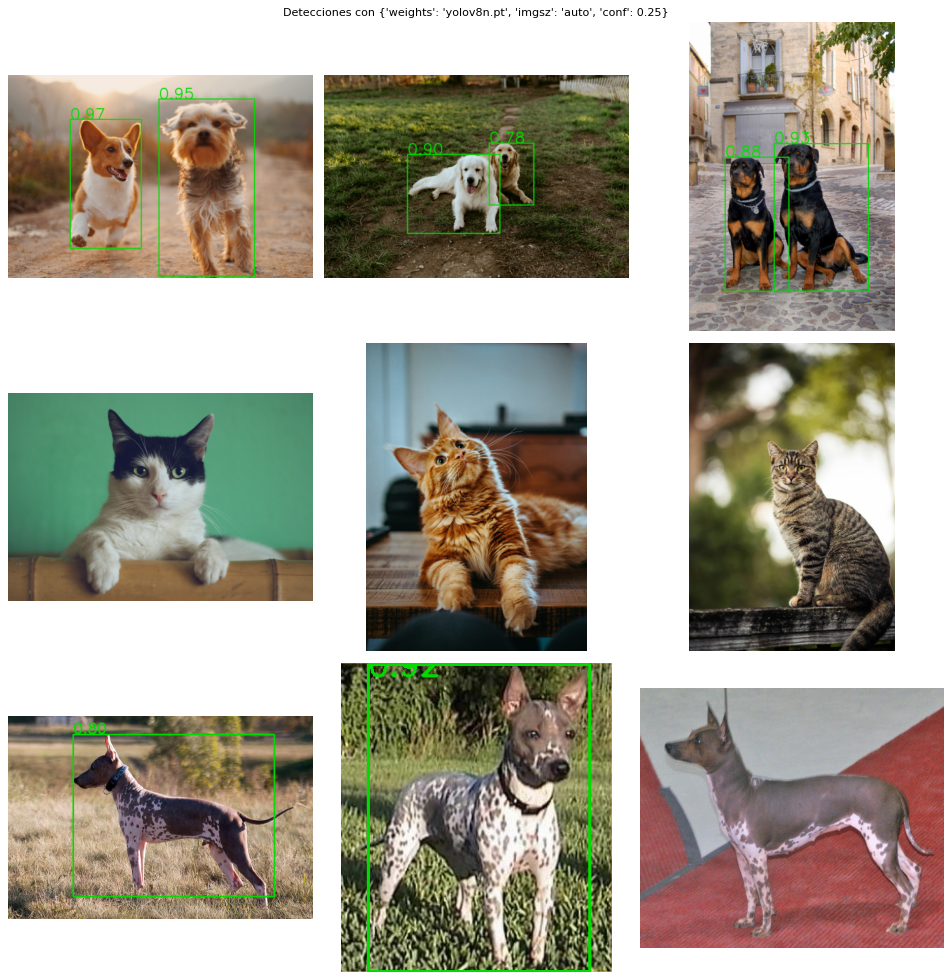

In [40]:
from lib.visualization.explain import draw_boxes

# El detector de la app con la configuracion elegida (imgsz=None: adaptativo).
app_detector = DetectionService(classifier, str(YOLO_DIR / CHOSEN["weights"]), CHOSEN["conf"],
                                settings.yolo_dog_class_id, min_confidence=0.0)
shown = []
for g in ("independiente, varios", "independiente, sin perros", "independiente, un perro"):
    for image in images[g][:3]:
        shown.append(draw_boxes(image, app_detector.detect_dogs(image), max_side=480))
fig = show_grid(shown, cols=3, size=480, cell_inches=4.0, suptitle=f"Detecciones con {CHOSEN}")
plt.show()

**Lectura** (YOLOv8n con umbral 0,25 salvo que se indique; 700 imágenes de `test`, 118 fotos reales
de un perro, 9 escenas con varios perros y 7 sin perros).

| `imgsz` | `test` 224 px: detecta | Fotos de un perro: detecta / conteo exacto | Varios: conteo exacto | Sin perro: falsas alarmas |
|---|---|---|---|---|
| 320 | **0,85** | 0,85 / 0,83 | 0,44 | 0 de 7 |
| 640 | 0,58 | 0,91 / 0,88 | **0,67** | 1 de 7 |
| 1280 | 0,05 | 0,65 / 0,37 | 0,56 | 1 de 7 |
| **auto** (320 a 640) | **0,85** | 0,90 / 0,88 | **0,67** | 1 de 7 |

- **No hay un `imgsz` fijo que sirva para todo.** A las imágenes de 224 px, 640 las agranda casi tres
  veces y YOLO pierde el perro en 4 de cada 10; 1280 casi nunca lo encuentra. En las fotos reales pasa
  lo contrario: 320 pierde perros chicos y lejanos, y 1280 sobrecuenta (el conteo exacto cae a 0,37,
  probablemente porque toma partes del perro como perros aparte).
- **Elegido: `imgsz` adaptativo.** Usa el tamaño real de la imagen entre 320 y 640, y queda en el mejor
  valor medido de cada dominio: igual que 320 en `test` e igual que 640 en las escenas. En las fotos de un
  perro, 16 de las 118 caen en tamaños intermedios, y ahí pierde 1 imagen respecto de 640 (0,90 contra
  0,91), dentro del ruido. Se agregó como regla de `DetectionService`, sin variables nuevas.
- **`YOLO_CONF_THRESHOLD=0.25` (se mantiene).** Entre 0,15, 0,25 y 0,40 cambian 1 o 2 imágenes por
  grupo. Bajarlo no recupera los perros perdidos (YOLO no los ve ni con confianza baja) y subirlo empieza
  a perder perros en las escenas con varios. Con 9 y 7 escenas la evidencia es débil: se mantiene el
  valor por defecto, que además es el del enunciado.
- **La falsa alarma es el lobo blanco** (`no_dog_05`), detectado como perro con 0,81. Ningún umbral
  razonable lo filtra: COCO no tiene la clase lobo y para la red es un perro. El zorro (`no_dog_04`) solo
  aparece con 1280. Es una limitación del detector; el clasificador le asignaría alguna raza.
- **YOLOv8n contra YOLO11n:** el 11n es algo mejor en las fotos reales (0,95 contra 0,90 de detección
  con la regla adaptativa, 6 imágenes de 118) y peor en `test` a 320 (0,84 contra 0,85). La latencia en
  CPU es parecida (en la CPU de Colab, unos 35 a 45 ms por imagen a 320 y entre 85 y 135 ms a 640). Se mantiene
  **YOLOv8n**: la diferencia es chica y es el modelo que trae el enunciado.
- **IoU del NMS:** 0,45 y 0,7 dan el mismo conteo en las escenas con perros superpuestos (6 de 9
  exactos, 3 de menos). Se mantiene 0,7, el valor por defecto: los perros que faltan no los suprime el
  NMS, YOLO directamente no los detecta.

### Umbral de confianza del clasificador (`CLASSIFIER_MIN_CONFIDENCE`, D-27)

En la Etapa 3, si la probabilidad de la raza predicha queda bajo `CLASSIFIER_MIN_CONFIDENCE` la app
responde `unknown` en vez de mostrar una raza dudosa. Es **clasificación selectiva**: se cambia cobertura
(proporción de recortes con respuesta) por precisión de lo que se responde. La probabilidad softmax de
una red profunda suele estar sobreconfiada (Guo et al., 2017), así que no se lee como probabilidad real:
el umbral se **calibra con datos**.

Criterio (D-27): sobre `valid`, la curva de riesgo-cobertura (accuracy de lo aceptado contra proporción
aceptada) y el **menor umbral con accuracy aceptada >= 95 %**; el menor porque es el que más cobertura
conserva. Después se mide una sola vez en `test` con ese umbral fijo. `valid` ya se usó para elegir la
variante y la época, así que su accuracy es algo optimista; por eso se confirma en `test`.

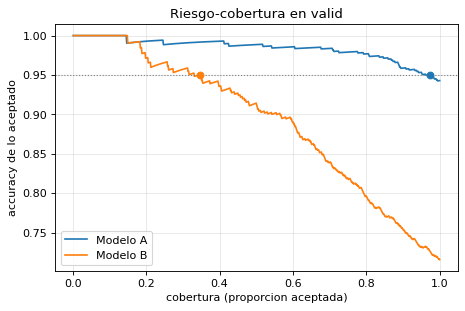

,umbral (valid),cobertura valid,accuracy aceptada valid,cobertura test,accuracy aceptada test,errores rechazados test
modelo,,,,,,
Modelo A,0.294,0.973,0.95,0.961,0.948,0.340
Modelo B,0.654,0.346,0.95,0.314,0.936,0.933


In [41]:
from lib.evaluation.classification import apply_confidence_threshold, confidence_threshold, risk_coverage

fig, ax = plt.subplots(figsize=(6.5, 4))
rows = []
for (label, name), test_pred in zip(MODELS.items(), (pred_a, pred_b)):
    classifier.set_active_model(name)
    valid_pred = classifier.predict_split("valid")
    curve = risk_coverage(valid_pred["probs"], valid_pred["y_true"])
    chosen = confidence_threshold(valid_pred["probs"], valid_pred["y_true"], target_accuracy=0.95)
    applied = apply_confidence_threshold(test_pred["probs"], test_pred["y_true"], chosen["threshold"])
    ax.plot(curve["coverage"], curve["accuracy"], label=label)
    ax.scatter([chosen["coverage"]], [chosen["accuracy"]], zorder=3)
    rows.append({"modelo": label, "umbral (valid)": round(chosen["threshold"], 3),
                 "cobertura valid": round(chosen["coverage"], 3), "accuracy aceptada valid": round(chosen["accuracy"], 3),
                 "cobertura test": round(applied["coverage"], 3), "accuracy aceptada test": round(applied["accuracy"], 3),
                 "errores rechazados test": round(applied["errors_rejected"], 3)})
classifier.set_active_model("resnet18_finetuned")
ax.axhline(0.95, color="gray", linestyle=":", linewidth=1)
ax.set(xlabel="cobertura (proporcion aceptada)", ylabel="accuracy de lo aceptado", title="Riesgo-cobertura en valid")
ax.legend()
plt.show()
min_conf_table = pd.DataFrame(rows).set_index("modelo")
display(min_conf_table)

**Lectura.**

| Modelo | Umbral (valid) | Cobertura valid | Accuracy aceptada valid | Cobertura test | Accuracy aceptada test | Errores rechazados test |
|---|---|---|---|---|---|---|
| A | 0,294 | 0,973 | 0,950 | 0,961 | 0,948 | 34 % |
| B | 0,654 | 0,346 | 0,950 | 0,314 | 0,936 | 93 % |

- **Para el Modelo A alcanza un umbral bajo.** Sin umbral ya acierta el 94,3 % de `valid`; con 0,294
  deja sin respuesta el 2,7 % de `valid` (3,9 % de `test`) y con eso descarta un tercio de los errores.
  En `test` la accuracy aceptada queda en 0,948, apenas bajo el 0,95 buscado: era esperable, porque
  `valid` ya se había usado para elegir la variante y la época y su número es algo optimista.
- **Para el Modelo B el criterio lo vuelve inútil:** para llegar al 95 % tiene que rechazar dos de cada
  tres imágenes. Otra razón para que la Etapa 3 use el Modelo A.
- **El umbral no arregla los errores seguros:** los 18 errores con probabilidad de 0,5 o más (sección
  10) pasan cualquier umbral razonable. Subirlo a 0,5 rechazaría el 66 % de los errores pero también el
  14 % de las imágenes.
- **Valor propuesto: `CLASSIFIER_MIN_CONFIDENCE=0.30`** con el Modelo A (el umbral de `valid`
  redondeado). Queda una salvedad: se calibró con imágenes del dataset, y en la Etapa 3 el clasificador
  recibe recortes de YOLO de fotos reales, donde es de esperar que la confianza baje y aparezcan más
  `unknown`. Se revisa con el conjunto independiente (sección 8).

## 13. Comparación y elección final

### Modelo A contra Modelo B sobre `test`

Las dos predicciones son sobre las **mismas** 700 imágenes, así que se comparan de forma pareada:

- **Intervalo bootstrap del 95 %** de la accuracy de cada modelo (2.000 remuestreos de las 700 imágenes).
- **Prueba de McNemar** (exacta): solo cuentan las imágenes donde un modelo acierta y el otro no. Si
  esos dos conteos son muy distintos, la diferencia no es casualidad. Es más sensible que comparar los
  dos intervalos, porque usa el emparejamiento.

In [42]:
from lib.evaluation.classification import bootstrap_ci, mcnemar_test

correct_a = pred_a["y_true"] == pred_a["y_pred"]
correct_b = pred_b["y_true"] == pred_b["y_pred"]
rows = []
for name, metrics, correct in [("Modelo A (ResNet18)", metrics_a, correct_a), ("Modelo B (CNN propia)", metrics_b, correct_b)]:
    _, low, high = bootstrap_ci(correct)
    rows.append({"modelo": name, **{k: round(v, 4) for k, v in metrics.items()}, "accuracy IC95": f"[{low:.3f}, {high:.3f}]"})
display(pd.DataFrame(rows).set_index("modelo"))
test = mcnemar_test(correct_a, correct_b)
print(f"McNemar: solo A acierta {test['only_a']}, solo B acierta {test['only_b']}, p = {test['p_value']:.2e}")

,accuracy,precision,recall,specificity,f1,accuracy IC95
modelo,,,,,,
Modelo A (ResNet18),0.9243,0.9333,0.9243,0.9989,0.9230,"[0.904, 0.943]"
Modelo B (CNN propia),0.7029,0.7213,0.7029,0.9957,0.6983,"[0.670, 0.739]"


McNemar: solo A acierta 175, solo B acierta 20, p = 4.25e-32


**Lectura.**

| Modelo | accuracy en `test` | IC 95 % (bootstrap) | F1 |
|---|---|---|---|
| A (ResNet18 finetune + pesos de clase) | 0,9243 | [0,904; 0,943] | 0,9230 |
| B (CNN propia) | 0,7029 | [0,670; 0,739] | 0,6983 |

- **La diferencia es clara.** Los intervalos no se superponen, y McNemar lo confirma: hay 175
  imágenes que solo acierta A y 20 que solo acierta B (p = 4,3e-32).
- **No es solo que A acierte más: B casi no aporta aciertos propios.** Las 20 imágenes que solo
  acierta B son el 3 % de `test`, así que combinar los dos modelos tendría poco para ganar.
- **Para clasificar, la app usa el Modelo A.**

### Tabla final y elección

Todo junto: la Etapa 1 (búsqueda por vecinos, sección 9), la Etapa 2 (clasificador sobre `test`) y el
costo (sección 11). La accuracy "por vecinos" es la de la raza votada por los 10 vecinos más parecidos de
`train`, sin umbral; la "del clasificador" es la de la cabeza entrenada.

In [43]:
final = pd.DataFrame({
    "accuracy test (clasificador)": [None, metrics_a["accuracy"], metrics_b["accuracy"]],
    "F1 test (clasificador)": [None, metrics_a["f1"], metrics_b["f1"]],
    "accuracy test (vecinos)": emb_table["accuracy"].to_numpy(),
    "NDCG@10": emb_table["ndcg@10"].to_numpy(),
    "silueta": emb_table["silueta (test)"].to_numpy(),
}, index=["baseline (ResNet50)", "Modelo A", "Modelo B"])
final = final.join(cost_table)
display(final.round(4))

,accuracy test (clasificador),F1 test (clasificador),accuracy test (vecinos),NDCG@10,silueta,parametros,MB .pth,dimension,ms CPU .pth,MB .onnx,ms CPU .onnx
baseline (ResNet50),NaN,NaN,0.9429,0.9016,0.2969,23508032,97.8,2048,123.2,NaN,NaN
Modelo A,0.9243,0.9230,0.9400,0.9185,0.3032,11212422,42.9,512,80.0,42.8,36.2
Modelo B,0.7029,0.6983,0.7043,0.5961,0.0596,1063014,4.1,256,39.5,4.1,16.1


**Elección.**

- **Clasificación (Etapas 2 y 3): Modelo A.** Acierta el 92,4 % de `test` contra el 70,3 % del B, la
  diferencia es significativa (McNemar, sección 13) y con `CLASSIFIER_MIN_CONFIDENCE=0.30` responde el
  96 % de las imágenes con 94,8 % de acierto. El Modelo B es diez veces más liviano, pero 80 ms contra
  40 ms por imagen en CPU no justifican perder 22 puntos de accuracy en esta app.
- **Búsqueda (`EMBEDDING_MODEL`): `baseline`.** En `test` el Modelo A ordena apenas mejor (NDCG@10
  +0,017) y acierta lo mismo por vecinos, pero en fotos reales el baseline acierta 0,797 contra 0,585
  (McNemar p = 2e-5, sección 9), y la app recibe fotos reales. El costo es aceptable: el embedding tarda
  123 ms en lugar de 80 y ocupa 8 KB por imagen en lugar de 2 KB. Además, no hay que reindexar la galería
  ni calibrar el umbral de `unknown` de la Etapa 1 para otro modelo: se calibra con los embeddings del
  baseline (sección 5).

**Búsqueda por similitud contra clasificación supervisada.** En `test` aciertan parecido (0,943 por
vecinos del baseline, 0,924 con el clasificador A). En fotos reales la búsqueda con el baseline acierta
**más** que el clasificador A con el recorte de YOLO (0,797 contra 0,644): sus rasgos generales se
transfieren mejor que los del modelo ajustado al dataset.

- **Búsqueda por similitud.** Para sumar una raza alcanza con indexar sus fotos, sin reentrenar; la
  respuesta se explica sola (estas son las imágenes más parecidas) y el umbral sobre el mejor vecino da un
  rechazo natural. A cambio, guarda y recorre toda la galería (crece con cada imagen), depende de que la
  galería esté bien etiquetada y el umbral se calibra para cada modelo de embeddings.
- **Clasificación supervisada.** Una sola pasada por la red, sin base de datos, y una probabilidad por
  raza que se puede calibrar (sección 12). A cambio, el conjunto de razas queda fijo: sumar una raza
  obliga a reentrenar, y una raza que no vio la asigna igual a alguna de las 70.
- **Cuándo conviene cada una:** la búsqueda cuando el catálogo cambia seguido o se quiere mostrar
  ejemplos parecidos; el clasificador cuando las clases son fijas y se necesita una respuesta rápida con
  una confianza calibrada. La app usa las dos con el mismo modelo, cada una en su pestaña.

**Trade-offs.** El Modelo A está en el punto medio: la mitad de parámetros y dos tercios de la latencia del baseline,
la mejor accuracy, y 43 MB que entran sin problema en el contenedor. El Modelo B solo convendría en un
dispositivo muy limitado (4 MB, 16 ms con ONNX), aceptando bastante más error. ONNX mejora la latencia de
los dos sin perder precisión; no se usa por defecto para no sumar otro formato a la entrega (D-09).

## 14. Descargar los checkpoints

Descargalos y colocalos en `models/` de tu entorno local para que la aplicación los use.
Recordá publicarlos en un link público de solo lectura y ponerlo en el README y en el PR.

In [44]:
!ls -lh "{settings.model_path}"

try:
    from google.colab import files

    for name in (settings.resnet18_model_name, settings.cnn_custom_model_name):
        files.download(str(settings.model_path / name))
        files.download(str(settings.model_path / (Path(name).stem + "_history.json")))
except ImportError:
    print("Fuera de Colab: los checkpoints quedan en", settings.model_path)

total 47M
-rw------- 1 root root  795 Nov 26 13:32 cnn_custom.done.json
-rw------- 1 root root  20K Nov 26 13:32 cnn_custom_history.json
-rw------- 1 root root 4.1M Nov 26 13:30 cnn_custom.pth
-rw------- 1 root root  819 Nov 26 12:00 resnet18_finetuned.done.json
-rw------- 1 root root 6.3K Nov 26 12:00 resnet18_finetuned_history.json
-rw------- 1 root root  43M Nov 26 11:58 resnet18_finetuned.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>